[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Y-Robin/MachineLearningKurs/blob/main/cheatsheet/Machine_Learning_CheatSheet.ipynb)

**In Colab:** Zuerst die folgende Setup-Zelle ausführen. [Anleitung zum Start](https://colab.research.google.com/github/Y-Robin/MachineLearningKurs/blob/main/set1-python-grundlagen/00_start_mit_google_colab.ipynb).


In [ ]:
# Nur in Google Colab: Repository, Bibliotheken und Arbeitsordner einrichten.
import importlib.util

if (importlib.util.find_spec("google") is not None
        and importlib.util.find_spec("google.colab") is not None):
    from pathlib import Path
    import runpy
    import subprocess

    repo = Path("/content/MachineLearningKurs")
    if not repo.exists():
        subprocess.check_call(["git", "clone", "--depth", "1", "--branch", "main",
                               "https://github.com/Y-Robin/MachineLearningKurs.git", str(repo)])
    runpy.run_path(str(repo / "colab_setup.py"))["setup"](
        'cheatsheet/Machine_Learning_CheatSheet.ipynb', cpu=False)


# Machine Learning CheatSheet

Rezepte passend zum Kurs. Kernel: Kursumgebung. Von oben nach unten ausführen.

Geprüfte Versionen: scikit-learn 1.9.1, numpy 2.4.6, pandas 3.1.0.
Der Transfer-Learning-Ausschnitt ist ausdrücklich nur im Originalnotebook ausführbar.

In [1]:

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, f1_score,
    mean_absolute_error, mean_squared_error, r2_score)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "requirements.txt").exists())


## 01 Methoden im Machine Learning

Vom Rohdatensatz bis zur überprüften Vorhersage. Dieses Nachschlageheft verbindet die Methoden aus Set 3 bis 15 mit kurzen Python-Rezepten und konkreten Kursdateien. Die erweiterte Bildfassung zeigt EDA und Modell-Diagnostik direkt bei den jeweiligen Methoden.

**Merksatz:** Erst die spätere Anwendung festlegen, dann Daten aufteilen. Alle gelernten Schritte gehören in die Trainings- und Validierungsschleife.

Kursbezug: Kursübersicht: README.md

| Seiten | Nachschlagen |
| --- | --- |
| 2–9 | Imports, Datensätze und EDA mit sechs Bildseiten |
| 10–13 | Vorverarbeitung und eigene Merkmale |
| 14–18 | Splits, CV und seltene Klassen |
| 19–20 | Metriken und Diagnoseplots |
| 21–30 | Überwachte Modelle und CRF |
| 31–34 | Zeitreihen und Prognosen |
| 35–38 | MLP, CNN und Transfer Learning |
| 39–44 | PCA, NMF, t-SNE und Cluster |
| 45–48 | Anomalien, Speichern und Transformer-Klasse |

**So benutzt du das Heft**

Jede Methodenseite enthält Zweck, Code, Ergebnis oder erwartete Ausgabe und einen Verweis auf das Kursnotebook. Die Rezepte sind gekürzte, an den Kurs angelehnte Beispiele; keine wortgetreuen Abschriften.

**Code ausführen**

Das begleitende Notebook im Ordner cheatsheet von oben nach unten mit der Kursumgebung ausführen. Die gemeinsame Importzelle gilt für alle Rezepte. Die Modellseiten nennen ihre Datenbasis ausdrücklich.

**Ergebnisse lesen**

Neu ausgeführte Beispiele verwenden random_state=42. Zahlen gelten nur für den genannten Split und die jeweilige Datenbasis. Das Heft ersetzt keinen fairen Benchmark auf identischen Daten.

## 02 Imports und gemeinsame Daten

Die folgenden zwei kleinen Datensätze werden auf den Modellseiten wiederverwendet: Halbmonde für nichtlineare Klassifikation und die simulierten Mietdaten aus Set 5 für Regression.

**Merksatz:** X enthält Merkmale als 2D-Matrix, y enthält Zielwerte. Xct/Xce stehen für Training/Test der Klassifikation, Xrt/Xre für Regression.

Kursbezug: Set 5: 01_lineare_regression.ipynb; Set 10: 01_svm_klassifikation.ipynb

In [2]:

from sklearn.datasets import make_moons
Xc, yc = make_moons(n_samples=500, noise=.22,
                   random_state=42)
Xct, Xce, yct, yce = train_test_split(
    Xc, yc, test_size=.25, stratify=yc, random_state=42)

rng = np.random.default_rng(42)
flaeche = rng.uniform(25, 130, 120)
miete = 8.5*flaeche + 320 + rng.normal(0, 85, 120)
Xr = pd.DataFrame({"flaeche_qm": flaeche.round(1)})
yr = pd.Series(miete.round(2), name="miete_euro")
Xrt, Xre, yrt, yre = train_test_split(
    Xr, yr, test_size=.25, random_state=42)
print("Klassifikation:", Xct.shape, Xce.shape)
print("Regression:", Xrt.shape, Xre.shape)
plt.show()

Klassifikation: (375, 2) (125, 2)
Regression: (90, 1) (30, 1)


**Gemeinsame Imports**

Im Notebook stehen NumPy als np, pandas als pd, Matplotlib als plt, Path, sys, train_test_split, Pipeline, make_pipeline, StandardScaler, SimpleImputer sowie accuracy_score, f1_score, mean_absolute_error, mean_squared_error und r2_score in der ersten Zelle.

**Bewertungsregel**

Die festen Modelle dieses Hefts sind didaktische Einzelrezepte. Bei eigener Modellauswahl zunächst ausschließlich innerhalb der Entwicklungsdaten vergleichen; den Test erst nach der Auswahl auswerten.

## 03 Datensätze passend zur Aufgabe

Für Klassifikation ist y eine Klasse, für Regression eine Zahl. Ob ein Datensatz eine Zufallsaufteilung erlaubt, hängt von Messaufbau, Gruppen und Zeitabhängigkeit ab.

**Merksatz:** Die Zieldefinition entscheidet über das Verfahren. Dieselbe Tabelle kann mehrere Aufgaben erlauben, benötigt dann aber jeweils eine klare Zielvariable.

Kursbezug: Set 3: daten/README.md; Sets 5, 7–9, 12, 14 und 15

In [3]:

from sklearn.datasets import load_iris, load_digits
iris = load_iris(as_frame=True)
print("Iris:", iris.data.shape, iris.target.nunique())
daten = ROOT / "set3-datenanalyse-und-visualisierung/daten"
penguins = pd.read_csv(daten / "palmer_penguins.csv")
wein = pd.read_csv(daten / "wine_quality_red.csv", sep=";")
print("Penguins:", penguins.shape, "Wein:", wein.shape)
plt.show()

Iris: (150, 4) 3
Penguins: (344, 8) Wein: (1599, 12)


| Daten im Kurs | Aufgabe / Besonderheit |
| --- | --- |
| Iris / WDBC Breast Cancer | Art / Diagnose; tabellarische Klassifikation |
| Palmer Penguins | species klassifizieren; Körpermaße als Merkmale |
| SMS Spam / Banknoten | Spam erkennen / Echtheit klassifizieren |
| AI4I Predictive Maintenance | Machine failure; seltene positive Klasse |
| Mietdaten / Sinusdaten | Regression; kontrollierte Simulationen |
| Wine Quality | quality als Zahl oder explizit definierte Klasse |
| Bike Sharing / Energie | cnt / Appliances; chronologische Prognose |
| CWRU / künstliche Spektren | Signalmerkmale / additive NMF-Bausteine |
| Digits / make_moons / make_blobs | Bilder / Klassifikation / Cluster-Demos |
| Kaggle in Set 3 | Titanic, House Prices, Credit Card Fraud; manuell laden |

**Zielleckage vermeiden**

AI4I: Fehleruntertypen können das Ziel direkt verraten. Bike Sharing: casual + registered = cnt, deshalb keine Zielbestandteile als Eingaben verwenden. IDs, spätere Messwerte und diagnostische Hilfsspalten prüfen.

**Zahlen sind keine garantierten Abstände**

Wine quality ist eine ordinale Bewertung. Regression behandelt Abstände wie Zahlenabstände; Klassifikation beantwortet eine andere, vorher definierte Frage.

## 04 Fehlende Werte sichtbar machen

Vor dem Modellieren prüfen wir Vollständigkeit und Muster fehlender Werte. Balken zeigen die Häufigkeit, eine Fehlwertmatrix zeigt, ob Spalten in denselben Zeilen ausfallen.

**Merksatz:** Ein fehlender Wert ist nicht automatisch zufällig. Muster erst verstehen, dann eine Imputationsstrategie festlegen.

Kursbezug: Set 3: 02_eda_palmer_penguins.ipynb; Set 4: 01_daten_verstehen_und_visualisieren.ipynb

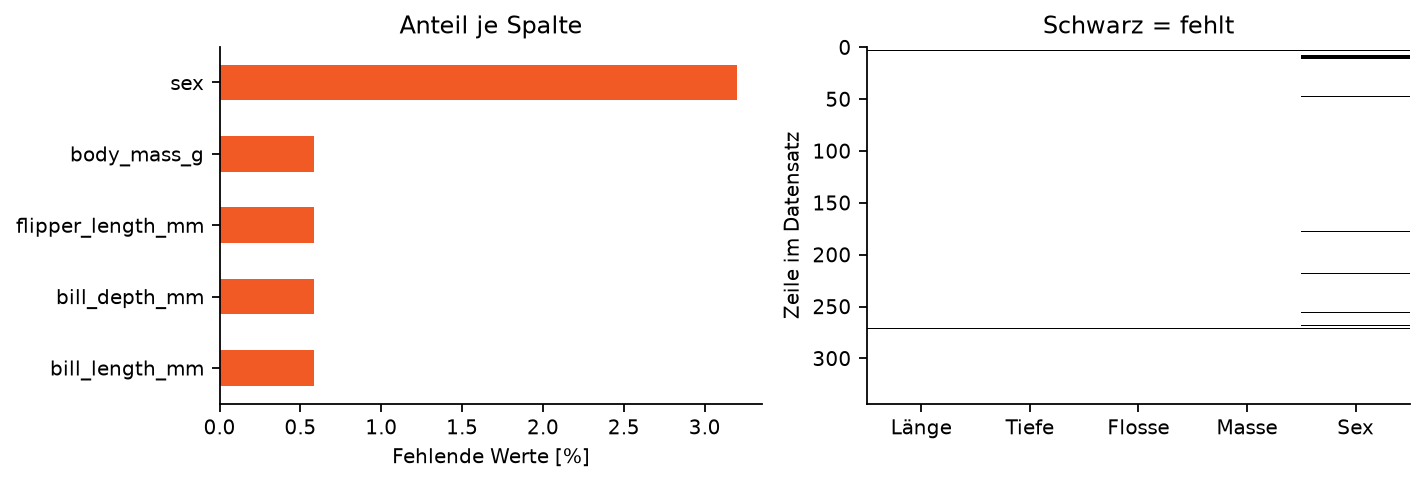

In [4]:

cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm",
        "body_mass_g", "sex"]
missing = penguins[cols].isna()
fig, ax = plt.subplots(1, 2, figsize=(9, 3.1))
(100*missing.mean()).plot.barh(ax=ax[0], color="#f15a24")
ax[0].set(xlabel="Fehlende Werte [%]", title="Anteil je Spalte")
ax[1].imshow(missing, aspect="auto", cmap="Greys", interpolation="nearest")
ax[1].set_xticks(range(len(cols)), ["Länge", "Tiefe", "Flosse", "Masse", "Sex"])
ax[1].set(ylabel="Zeile im Datensatz", title="Schwarz = fehlt")
fig.tight_layout()
plt.show()

**Bild lesen**

sex enthält mehr Fehlwerte als die Körpermaße. Bei mehreren Körpermaßen liegen Fehlwerte in denselben Zeilen. Die Zeilenreihenfolge kann Hinweise auf gemeinsame Messausfälle geben.

**Nächster Schritt**

isna().sum() liefert die absoluten Zahlen. Vor Imputation klären, ob ein Messfehler, ein bestimmter Standort oder ein systematischer Ausfall dahintersteckt. Für Modellentscheidungen nur Trainingsdaten explorieren.

## 05 Histogramme und Verteilungen

Histogramme zeigen Schiefe, Häufungen und mehrere Gipfel. Gleiche Bins und Achsen helfen, Gruppen zu vergleichen; Rohdaten und Gruppenmischung können unterschiedlich aussehen.

**Merksatz:** Ein zweiter Gipfel kann eine echte Untergruppe statt eines Ausreißers sein. Verteilungen deshalb auch nach fachlichen Gruppen betrachten.

Kursbezug: Set 3: 02_eda_palmer_penguins.ipynb; 03_eda_wine_quality.ipynb

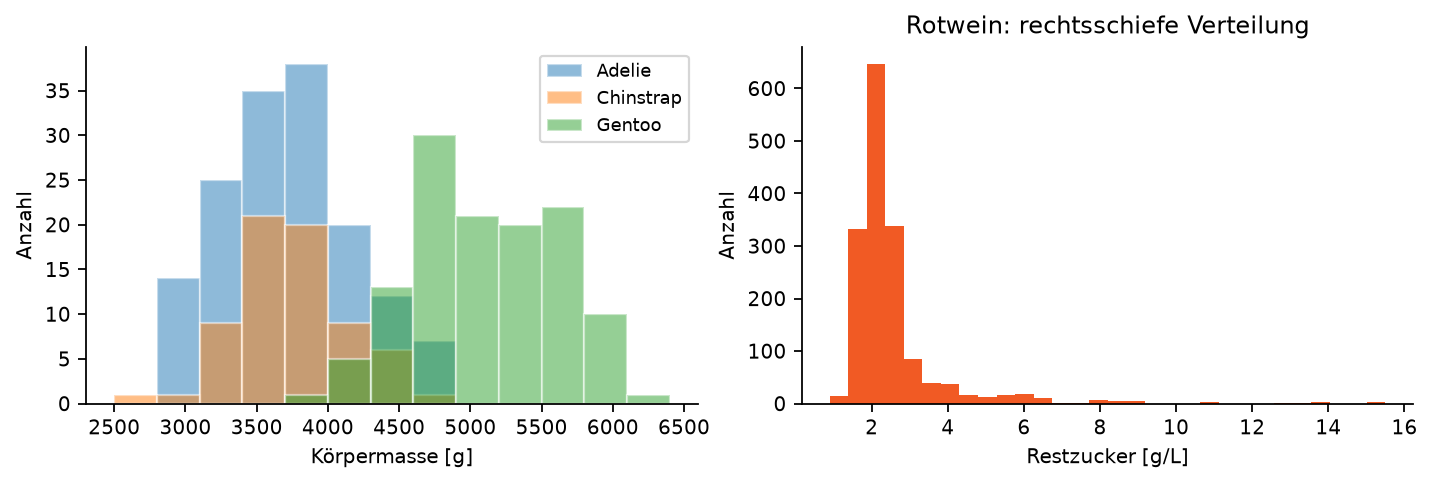

In [5]:

fig, ax = plt.subplots(1, 2, figsize=(9, 3.1))
bins = np.arange(2500, 6501, 300)
for art, gruppe in penguins.groupby("species"):
    ax[0].hist(gruppe.body_mass_g.dropna(), bins=bins,
               alpha=.5, label=art, edgecolor="white")
ax[0].set(xlabel="Körpermasse [g]", ylabel="Anzahl")
ax[0].legend(fontsize=8)
ax[1].hist(wein["residual sugar"], bins=30, color="#f15a24")
ax[1].set(xlabel="Restzucker [g/L]", ylabel="Anzahl",
          title="Rotwein: rechtsschiefe Verteilung")
fig.tight_layout()
plt.show()

**Bild lesen**

Gentoo liegt bei der Körpermasse überwiegend weiter rechts. Restzucker ist rechtsschief: wenige hohe Werte verlängern den rechten Rand; der Mittelwert kann deshalb stärker als der Median verschoben sein.

**Code variieren**

Mit density=True wird die Dichte statt der Anzahl gezeigt. Für positive rechtsschiefe Größen kann eine fachlich passende Log-Transformation helfen; sie muss anschließend auch bei neuen Daten identisch angewendet werden.

## 06 Boxplots und einzelne Messpunkte

Boxplots vergleichen Lage und Streuung zwischen Gruppen. Zusätzliche Messpunkte zeigen Stichprobengröße, Häufungen und die Verteilung, die eine Box allein verbergen kann.

**Merksatz:** Ein Punkt außerhalb der Whisker ist nach der Boxplot-Regel auffällig. Er ist dadurch noch kein falscher Messwert und wird nicht automatisch gelöscht.

Kursbezug: Set 3: 02_eda_palmer_penguins.ipynb; 03_eda_wine_quality.ipynb

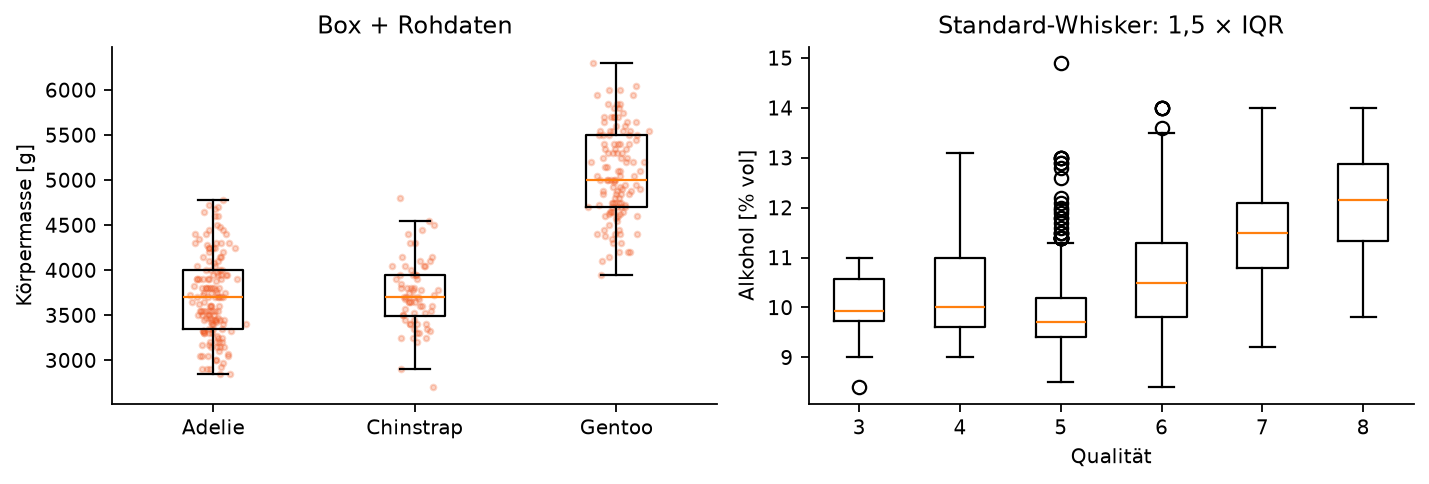

In [6]:

arten = sorted(penguins.species.dropna().unique())
fig, ax = plt.subplots(1, 2, figsize=(9, 3.1))
werte = [penguins.loc[penguins.species==a, "body_mass_g"].dropna()
         for a in arten]
ax[0].boxplot(werte, tick_labels=arten, showfliers=False)
rng = np.random.default_rng(42)
for i, vals in enumerate(werte, 1):
    ax[0].scatter(i+rng.normal(0,.055,len(vals)), vals,
                  s=6, alpha=.25, color="#f15a24")
ax[0].set(ylabel="Körpermasse [g]", title="Box + Rohdaten")
qual = sorted(wein.quality.unique())
ax[1].boxplot([wein.loc[wein.quality==q, "alcohol"] for q in qual],
              tick_labels=qual)
ax[1].set(xlabel="Qualität", ylabel="Alkohol [% vol]",
          title="Standard-Whisker: 1,5 × IQR")
fig.tight_layout()
plt.show()

**Box lesen**

Die Linie ist der Median, die Box reicht vom 25%- bis zum 75%-Quantil. IQR ist die Boxhöhe. Whisker enden bei den äußersten Datenpunkten innerhalb der Grenzen Q1 - 1,5 IQR und Q3 + 1,5 IQR.

**Ergebnis einordnen**

Höhere Weinqualität geht hier tendenziell mit höherem Alkoholgehalt einher, aber die Verteilungen überlappen. Aus dieser EDA folgt weder eine perfekte Vorhersage noch ein kausaler Effekt.

## 07 Scatterplots nach Gruppen

Scatterplots zeigen Beziehungen zwischen zwei numerischen Merkmalen. Farbe und Transparenz machen Gruppen, Überlagerungen und Unterschiede in Steigung oder Streuung erkennbar.

**Merksatz:** Einen Zusammenhang in der Gesamttabelle immer auch innerhalb plausibler Gruppen ansehen. Mischungen können Korrelationen verstärken, abschwächen oder umkehren.

Kursbezug: Set 3: 02_eda_palmer_penguins.ipynb; 03_eda_wine_quality.ipynb

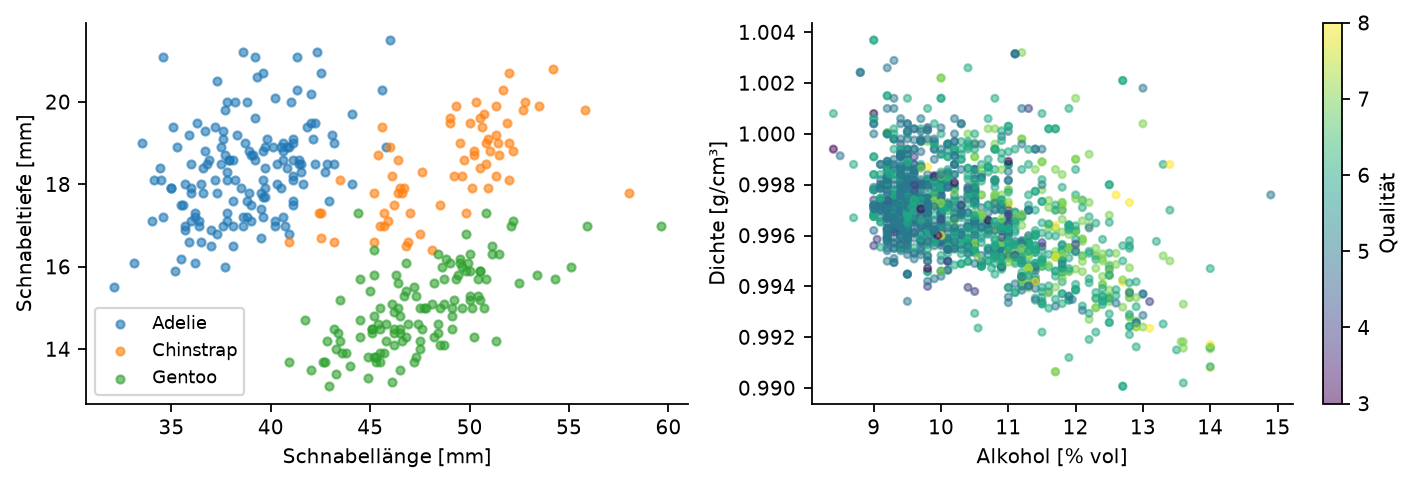

In [7]:

fig, ax = plt.subplots(1, 2, figsize=(9, 3.1))
for art, gruppe in penguins.groupby("species"):
    ax[0].scatter(gruppe.bill_length_mm, gruppe.bill_depth_mm,
                  s=13, alpha=.6, label=art)
ax[0].set(xlabel="Schnabellänge [mm]", ylabel="Schnabeltiefe [mm]")
ax[0].legend(fontsize=8)
pts = ax[1].scatter(wein.alcohol, wein.density, c=wein.quality,
                    cmap="viridis", s=10, alpha=.5)
ax[1].set(xlabel="Alkohol [% vol]", ylabel="Dichte [g/cm³]")
fig.colorbar(pts, ax=ax[1], label="Qualität")
fig.tight_layout()
plt.show()

**Bild lesen**

Die Pinguinarten bilden unterschiedlich gelegene Punktwolken. Bei Rotwein sind höhere Alkoholwerte häufig mit geringerer Dichte verbunden; die Qualitätsstufen bleiben jedoch stark überlagert.

**Viele Punkte**

alpha und kleine Marker reduzieren Überdeckung. Bei großen Tabellen hexbin oder eine 2D-Häufigkeitsdarstellung nutzen. Achsen und Einheiten angeben; eine Farbskala für Kategorien braucht klar unterscheidbare Klassenfarben.

## 08 Korrelationen als Heatmap

Eine Korrelationsmatrix fasst paarweise Zusammenhänge zusammen. Pearson misst lineare, Spearman monotone Beziehungen und ist bei Rängen oder stark schiefen Größen oft eine nützliche Ergänzung.

**Merksatz:** Korrelation ist kein Kausalnachweis. Eine hohe Korrelation zwischen Eingaben kann auch redundante Merkmale anzeigen.

Kursbezug: Set 3: 02_eda_palmer_penguins.ipynb; 03_eda_wine_quality.ipynb

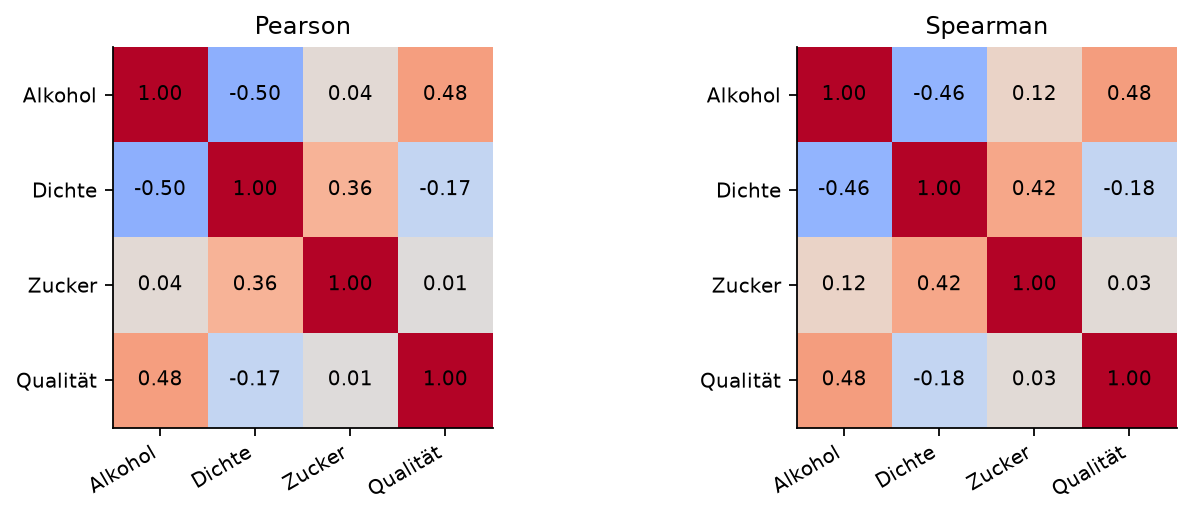

In [8]:

cols = ["alcohol", "density", "residual sugar", "quality"]
labels_corr = ["Alkohol", "Dichte", "Zucker", "Qualität"]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
for a, method in zip(ax, ["pearson", "spearman"]):
    corr = wein[cols].corr(method=method)
    im = a.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    a.set_xticks(range(4), labels_corr, rotation=30, ha="right")
    a.set_yticks(range(4), labels_corr)
    a.set_title(method.title())
    for i in range(4):
        for j in range(4):
            a.text(j, i, f"{corr.iloc[i,j]:.2f}",
                   ha="center", va="center", fontsize=9)
fig.tight_layout()
plt.show()

**Farben und Zahlen**

Rot bedeutet positive, Blau negative Korrelation; die Skala ist in beiden Bildern identisch von -1 bis 1. Die Diagonale ist immer 1. Alkohol und Qualität hängen positiv, Alkohol und Dichte negativ zusammen.

**Grenzen**

Pearson nahe 0 schließt einen gekrümmten Zusammenhang nicht aus. Fehlwerte können zu unterschiedlichen paarweisen Stichproben führen. Für fachliche Aussagen zusätzlich Scatterplots, Gruppenstruktur und Fallzahlen ansehen.

## 09 Mehrere Merkmale im Paarvergleich

Eine Scatter-Matrix zeigt für mehrere Merkmale alle paarweisen Beziehungen. Auf der Diagonale stehen Verteilungen; außerhalb der Diagonale Punktwolken.

**Merksatz:** Für wenige ausgewählte Merkmale ist die Matrix ein schneller Überblick. Bei vielen Spalten wird sie unlesbar; dann fachlich vorsortieren.

Kursbezug: Set 3: 02_eda_palmer_penguins.ipynb; Set 4: 01_daten_verstehen_und_visualisieren.ipynb

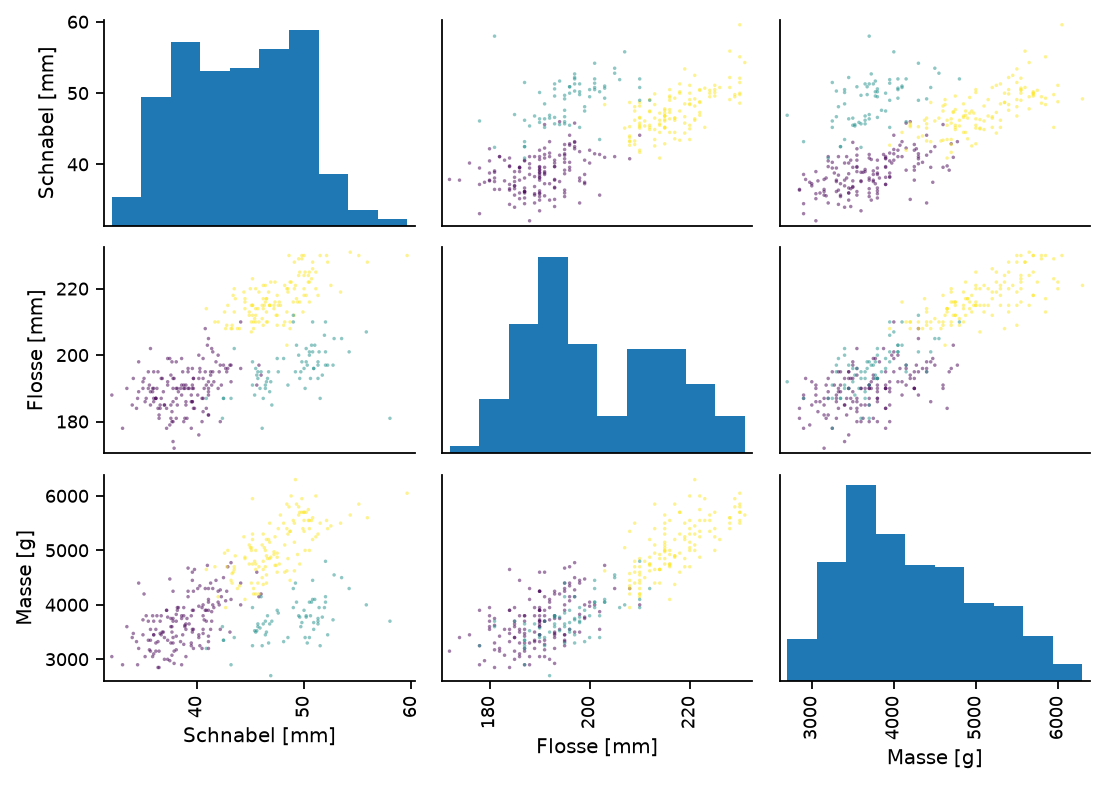

In [9]:

from pandas.plotting import scatter_matrix
cols = ["bill_length_mm", "flipper_length_mm", "body_mass_g"]
pairs = penguins.dropna(subset=cols+["species"]).copy()
kurz = pairs[cols].rename(columns={
    "bill_length_mm":"Schnabel [mm]",
    "flipper_length_mm":"Flosse [mm]", "body_mass_g":"Masse [g]"})
axes = scatter_matrix(kurz, c=pairs.species.astype("category").cat.codes,
    cmap="viridis", diagonal="hist", alpha=.5, s=10,
    figsize=(7, 5), grid=False)
axes[0,0].figure.tight_layout()
plt.show()

**Bild lesen**

Flossenlänge und Masse steigen in der Gesamttabelle gemeinsam. Die Farben markieren Arten; innerhalb einer Farbe kann der Zusammenhang anders aussehen. Gespiegelte Felder enthalten dieselben Punkte mit vertauschten Achsen.

**Gezielt weiterarbeiten**

Auffällige Paare anschließend groß als einzelnen Scatterplot untersuchen. Die Diagonale zeigt die Gesamtverteilung, keine getrennten Histogramme pro Farbe. Diese Ansicht dient der EDA und ist keine Modellbewertung.

## 10 Imputation und Standardisierung

SimpleImputer ersetzt fehlende Werte, StandardScaler bringt numerische Merkmale auf vergleichbare Skalen. Das ist besonders für kNN, SVM, lineare Regularisierung, PCA und MLP hilfreich.

**Merksatz:** fit lernt Median, Mittelwert und Streuung ausschließlich am Training. Für neue Daten wird nur transform aufgerufen.

Kursbezug: Set 4: 02_sklearn_transformer_basics.ipynb

In [10]:

train = pd.DataFrame({"alter": [20., 40., np.nan],
                      "umsatz": [100., 300., 200.]})
neu = pd.DataFrame({"alter": [np.nan], "umsatz": [400.]})
prep = make_pipeline(SimpleImputer(strategy="median"),
                     StandardScaler())
z_train = prep.fit_transform(train)
z_neu = prep.transform(neu)
print("Mediane:", prep[0].statistics_)
print("Training:\n", np.round(z_train, 3))
print("Neu:", np.round(z_neu, 3))
plt.show()

Mediane: [ 30. 200.]
Training:
 [[-1.225 -1.225]
 [ 1.225  1.225]
 [ 0.     0.   ]]
Neu: [[0.    2.449]]


**Wie rechnen?**

z = (x - Mittelwert des Trainings) / Standardabweichung des Trainings. StandardScaler verwendet ddof=0. Neue Daten dürfen Mittelwert und Streuung verändern; sie werden nicht erneut auf Mittelwert 0 angepasst.

**Alternativen**

Median ist relativ robust gegen Ausreißer. MinMaxScaler skaliert anhand des Trainingsbereichs; neue Werte können außerhalb von [0,1] liegen. RobustScaler nutzt Median und Quantilabstand. Bäume brauchen normalerweise keine Standardisierung.

**Fehlende Werte sind Information**

SimpleImputer(add_indicator=True) ergänzt Indikatoren für Spalten, die im Fit fehlende Werte enthielten. Gründe für fehlende Werte trotzdem prüfen. Zielwerte nicht ohne fachliche Begründung imputieren.

## 11 Vor und nach der Skalierung

Merkmale mit großen Zahlenbereichen dominieren unskalierte Distanzen. Ein direkter Vorher-nachher-Vergleich zeigt, wie Standardisierung die Skalen angleicht.

**Merksatz:** Standardisieren ändert Einheiten und Abstände, nicht die grundlegende Rangfolge der Werte innerhalb einer Spalte.

Kursbezug: Set 4: 02_sklearn_transformer_basics.ipynb

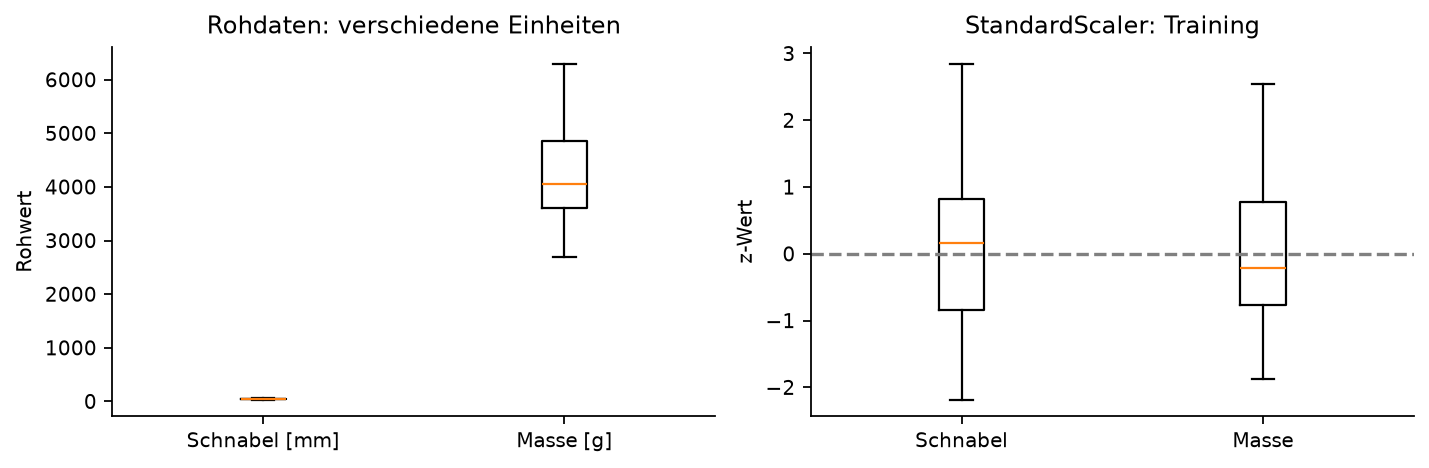

In [11]:

raw = penguins[["bill_length_mm", "body_mass_g"]].dropna()
raw_train, raw_test = train_test_split(raw, test_size=.25, random_state=42)
scaler_vis = StandardScaler().fit(raw_train)
z_vis = scaler_vis.transform(raw_train)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].boxplot(raw_train.to_numpy(), tick_labels=["Schnabel [mm]", "Masse [g]"])
ax[0].set(title="Rohdaten: verschiedene Einheiten", ylabel="Rohwert")
ax[1].boxplot(z_vis, tick_labels=["Schnabel", "Masse"])
ax[1].axhline(0, ls="--", color="grey")
ax[1].set(title="StandardScaler: Training", ylabel="z-Wert")
fig.tight_layout()
plt.show()

**Bild lesen**

Links wirkt der Schnabelbereich neben den Grammwerten fast wie eine Linie. Rechts liegen die Merkmale auf vergleichbaren Skalen. Die linke Darstellung ist absichtlich ein Beispiel für einen irreführenden gemeinsamen Rohwertmaßstab.

**Wichtig**

StandardScaler erzeugt keine Normalverteilung und entfernt keine Ausreißer. Die rechte Box muss nicht exakt um den Median 0 liegen, da nach Mittelwert und Standardabweichung skaliert wird.

## 12 Gemischte Tabellen als Pipeline

ColumnTransformer verarbeitet Zahlen und Kategorien getrennt. OneHotEncoder erzeugt Indikatorspalten, damit Kategorien keine künstliche numerische Reihenfolge erhalten.

**Merksatz:** Eine Pipeline verbindet Vorverarbeitung und Modell. Bei jedem CV-Fold werden beide ausschließlich am jeweiligen Training gelernt.

Kursbezug: Set 4: 03_preprocessing_mit_pipeline.ipynb; Set 5: 04_pipeline_palmer_penguins.ipynb

In [12]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
df = penguins.dropna(subset=["species"])
X = df[["bill_length_mm", "bill_depth_mm", "island", "sex"]]
y = df["species"]
Xt, Xe, yt, ye = train_test_split(
    X, y, stratify=y, test_size=.25, random_state=42)
num = make_pipeline(SimpleImputer(strategy="median"),
                    StandardScaler())
cat = make_pipeline(SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore"))
prep = ColumnTransformer([
    ("num", num, ["bill_length_mm", "bill_depth_mm"]),
    ("cat", cat, ["island", "sex"])])
penguin_model = Pipeline([("prep", prep),
    ("clf", LogisticRegression(max_iter=2000))])
penguin_model.fit(Xt, yt)
print("Accuracy:", round(penguin_model.score(Xe, ye), 3))
print("Merkmale:", len(prep.get_feature_names_out()))
plt.show()

Accuracy: 0.988
Merkmale: 7


**Unbekannte Kategorien**

handle_unknown="ignore" verhindert einen Fehler bei neuen Kategorien; die betreffende One-Hot-Gruppe wird null. Prüfen, ob dieses Verhalten für die Anwendung sinnvoll ist.

**Spalten bewusst wählen**

Spaltenlisten werden hier fachlich festgelegt. Statistische Feature-Auswahl, Imputation, Skalierung und PCA gehören bei Modellbewertung in die Pipeline. Einfache EDA-Fits auf allen Daten sind keine validierten Modelle.

## 13 Eigene Transformer und Signalmerkmale

Ein eigener Transformer bildet Fachwissen als reproduzierbaren Schritt ab. Im Kurs ergänzen Flächenprodukte die Iris-Merkmale; bei Sensorsignalen werden beispielsweise RMS und Spektralenergie pro Fenster gebildet.

**Merksatz:** Eine feste Rechenregel braucht kein Training. Sobald der Transformer Schwellen, Frequenzen oder Referenzen aus Daten lernt, geschieht das in fit am Training.

Kursbezug: Set 15: 02b_sklearn_eigener_transformer_schritt_fuer_schritt.ipynb; Set 3: sensor_features.py

In [13]:

# Importierbare Kursklasse, damit Speichern/Laden funktioniert.
sys.path.insert(0, str(ROOT / "set15-modelle-speichern-und-laden"))
from custom_transformer_einfach import FlaechenMerkmale
from sklearn.linear_model import LogisticRegression
it, ie, jt, je = train_test_split(iris.data, iris.target,
    stratify=iris.target, test_size=.25, random_state=42)
iris_model = make_pipeline(FlaechenMerkmale(),
    SimpleImputer(strategy="median"), StandardScaler(),
    LogisticRegression(max_iter=2000))
iris_model.fit(it, jt)
print("Merkmale:", FlaechenMerkmale().fit_transform(it).shape)
print("Accuracy:", round(iris_model.score(ie, je), 3))

sys.path.insert(0, str(ROOT / "set3-datenanalyse-und-visualisierung"))
from sensor_features import signal_merkmale
fs = 48000
t = np.arange(8192) / fs
signal = np.sin(2*np.pi*1000*t)  # kontrolliertes Testsignal
f = signal_merkmale(signal, fs=fs)
print("RMS:", round(f["rms"], 3),
      "Peak-Hz:", round(f["peak_frequenz_hz"], 1))
plt.show()

Merkmale: (112, 6)
Accuracy: 0.921
RMS: 0.707 Peak-Hz: 1002.0


**Aufbau der Klasse**

FlaechenMerkmale erbt von TransformerMixin und BaseEstimator. fit gibt self zurück; transform kopiert X und ergänzt kelch_flaeche sowie blueten_flaeche als Längen-Breiten-Produkte. Vollständiger Klassencode: Seite 48; importierbare Originaldatei: custom_transformer_einfach.py.

**Fenster und Frequenzen**

FFT-Frequenzauflösung: fs / Fensterlänge. Set 3 nutzt 8192 Samples, Mittelwertabzug und Hann-Fenster. Fenster derselben Aufnahme sind abhängig; bei Bewertung nach Aufnahme oder Lager trennen. Vier CWRU-Aufnahmen allein tragen keine belastbare Generalisierung auf neue Lager.

## 14 Split nach späterer Anwendung

Zufallssplits passen zu unabhängigen Zeilen. Gruppen müssen zusammenbleiben, wenn das Modell später neue Personen, Maschinen oder Aufnahmen sehen soll; Prognosen benötigen chronologische Splits.

**Merksatz:** Der Split simuliert die Zukunft der Anwendung. Ein technisch korrekter Zufallssplit kann bei abhängigen Messungen trotzdem die falsche Frage beantworten.

Kursbezug: Set 4: 04_daten_richtig_aufteilen.ipynb

In [14]:

from sklearn.model_selection import GroupShuffleSplit
# 60 % Training, 20 % Validierung, 20 % Test
ids = np.arange(len(yc))
dev, test = train_test_split(ids, test_size=.2,
    stratify=yc, random_state=42)
train, val = train_test_split(dev, test_size=.25,
    stratify=yc[dev], random_state=42)
print("Train/Val/Test:", len(train), len(val), len(test))

# Demo: 50 Maschinen mit je 10 aufeinanderfolgenden Zeilen
gruppen = np.repeat(np.arange(50), 10)
splitter = GroupShuffleSplit(n_splits=1, test_size=.2,
                             random_state=42)
tr, te = next(splitter.split(Xc, yc, groups=gruppen))
print("Gemeinsame Gruppen:",
      len(set(gruppen[tr]) & set(gruppen[te])))
# Zeitreihe: erst sortieren, dann ohne Mischen teilen
reihe = pd.Series(np.arange(100.))
zeit_train, zeit_test = reihe.iloc[:80], reihe.iloc[80:]
plt.show()

Train/Val/Test: 300 100 100
Gemeinsame Gruppen: 0


| Fall | Holdout / Kreuzvalidierung |
| --- | --- |
| Unabhängige Regression | Zufallssplit / KFold mit shuffle=True |
| Unabhängige Klassifikation | stratify=y / StratifiedKFold |
| Neue Gruppen | GroupShuffleSplit / GroupKFold |
| Gruppen und Klassenbalance | ggf. StratifiedGroupKFold; Balance prüfen |
| Vorhersage zukünftiger Werte | Zeit-Holdout / TimeSeriesSplit mit Lücke |

**Überlappende Zeitfenster**

Nicht nur Zeilenindizes prüfen: Trainingsziele dürfen nicht in den Validierungszeitraum ragen. Fenster, Forecast-Horizont und zeitliche Verfügbarkeit bestimmen die benötigte Lücke. Gruppen mit Zeitordnung erfordern oft einen eigenen Split.

## 15 Splits visuell kontrollieren

Splitdiagramme machen sichtbar, welche Beobachtungen in Training und Test landen. Besonders bei wiederholten Messungen ist damit eine zufällige Durchmischung von Maschinen schnell erkennbar.

**Merksatz:** Ein Splitplot ist ein Plausibilitätscheck. Ob Zeilen tatsächlich unabhängig sind, entscheidet der Messaufbau.

Kursbezug: Set 4: 04_daten_richtig_aufteilen.ipynb; 05_kreuzvalidierung_ohne_data_leakage.ipynb

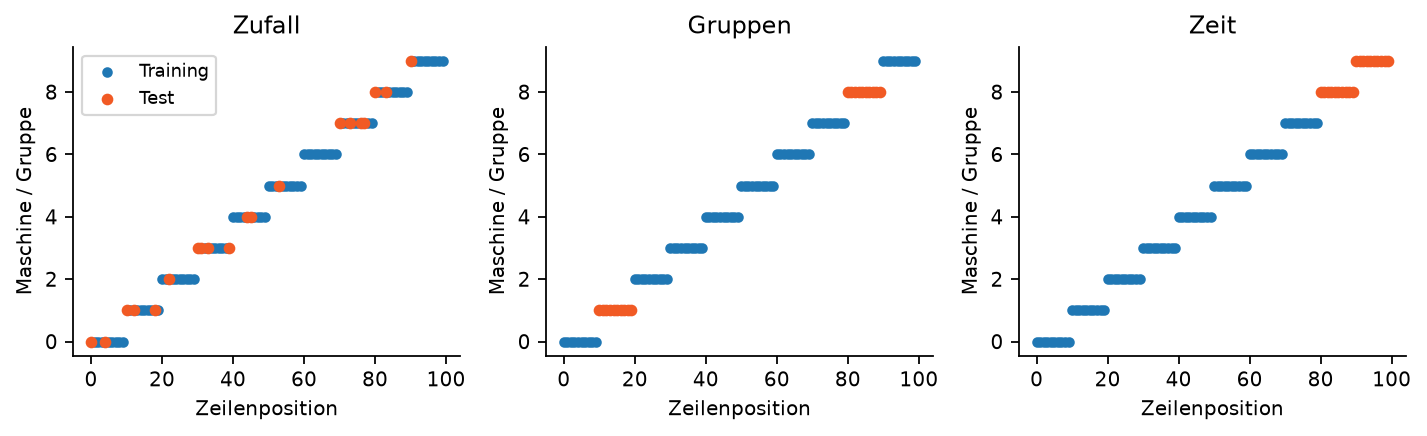

In [15]:

from sklearn.model_selection import GroupShuffleSplit
n_vis = 100
group_vis = np.repeat(np.arange(10), 10)
rand_tr, rand_te = train_test_split(np.arange(n_vis), test_size=.2, random_state=42)
gtr, gte = next(GroupShuffleSplit(n_splits=1, test_size=.2,
    random_state=42).split(np.zeros((n_vis,1)), groups=group_vis))
fig, ax = plt.subplots(1, 3, figsize=(9, 2.8))
splits_vis = [(rand_tr,rand_te), (gtr,gte), (np.arange(80),np.arange(80,100))]
for a, (tr,te), name in zip(ax, splits_vis, ["Zufall", "Gruppen", "Zeit"]):
    a.scatter(tr, group_vis[tr], s=14, label="Training")
    a.scatter(te, group_vis[te], s=18, label="Test", color="#f15a24")
    a.set(title=name, xlabel="Zeilenposition", ylabel="Maschine / Gruppe")
ax[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Bild lesen**

Beim Zufallssplit sind orange Testpunkte über fast alle Maschinen verteilt. Im Gruppensplit liegen ganze Maschinen im Test. Der Zeitsplit reserviert den rechten, späteren Bereich; er garantiert bei anderer Zeilensortierung keine Gruppentrennung.

**Kombinierte Anforderungen**

Wer neue Maschinen in der Zukunft vorhersagen will, muss Gruppen und Zeit gemeinsam berücksichtigen. Für Sequenzen, Personen oder Originalaufnahmen gelten entsprechende Gruppengrenzen.

## 16 Kreuzvalidierung und Tuning

Kreuzvalidierung schätzt die Streuung über mehrere Trainingsaufteilungen. GridSearchCV wählt Hyperparameter ausschließlich innerhalb der Entwicklungsdaten.

**Merksatz:** Testdaten bleiben bis nach der Auswahl unangetastet. Den besten Such-CV-Wert nicht als unabhängige Schätzung der endgültigen Güte verkaufen.

Kursbezug: Set 4: 05_kreuzvalidierung_ohne_data_leakage.ipynb; Set 6: 03_hyperparameter_tuning_regression.ipynb

In [16]:

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
dev_x, test_x, dev_y, test_y = train_test_split(
    Xc, yc, test_size=.2, stratify=yc, random_state=42)
pipe = Pipeline([("scale", StandardScaler()),
                 ("clf", LogisticRegression(max_iter=2000))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
suche = GridSearchCV(pipe, {"clf__C": [.01, .1, 1, 10]},
                     cv=cv, scoring="f1", n_jobs=1)
suche.fit(dev_x, dev_y)
print("Beste Parameter:", suche.best_params_)
print("Such-CV F1:", round(suche.best_score_, 3))
pred = suche.predict(test_x)
print("Finaler Test-F1:", round(f1_score(test_y, pred), 3))
plt.show()

Beste Parameter: {'clf__C': 0.1}
Such-CV F1: 0.855
Finaler Test-F1: 0.846


**Regression und Gruppen**

Für Regression beispielsweise KFold(5, shuffle=True, random_state=42) und scoring="neg_root_mean_squared_error" verwenden. Bei GroupKFold zusätzlich groups an fit bzw. cross_validate übergeben; eine normale KFold-Schleife schützt Gruppen nicht.

**Negative Fehlerscores**

scikit-learn maximiert Scores. Bei neg_mean_absolute_error oder neg_root_mean_squared_error das Vorzeichen zur Darstellung als Fehler umdrehen. Größere negative Scores bedeuten kleinere Fehler.

**Verschachtelte CV**

Wenn Modellfamilien und Parameter umfangreich verglichen werden und kein separater Test verfügbar ist: äußere CV für die Bewertung, innere CV für die Auswahl. Bei Zeit und Gruppen müssen beide Ebenen die Abhängigkeiten respektieren.

## 17 Tuningwerte mit Streuung zeigen

Ein einzelner bester CV-Wert verdeckt die Unterschiede zwischen Folds. Fehlerbalken zeigen, ob die Parameterwahl deutlich oder nur knapp besser abschneidet.

**Merksatz:** Die Standardabweichung über CV-Folds ist ein Streuungsmaß und kein unabhängiges Konfidenzintervall der zukünftigen Modellgüte.

Kursbezug: Set 6: 03_hyperparameter_tuning_regression.ipynb; Set 4: 05_kreuzvalidierung_ohne_data_leakage.ipynb

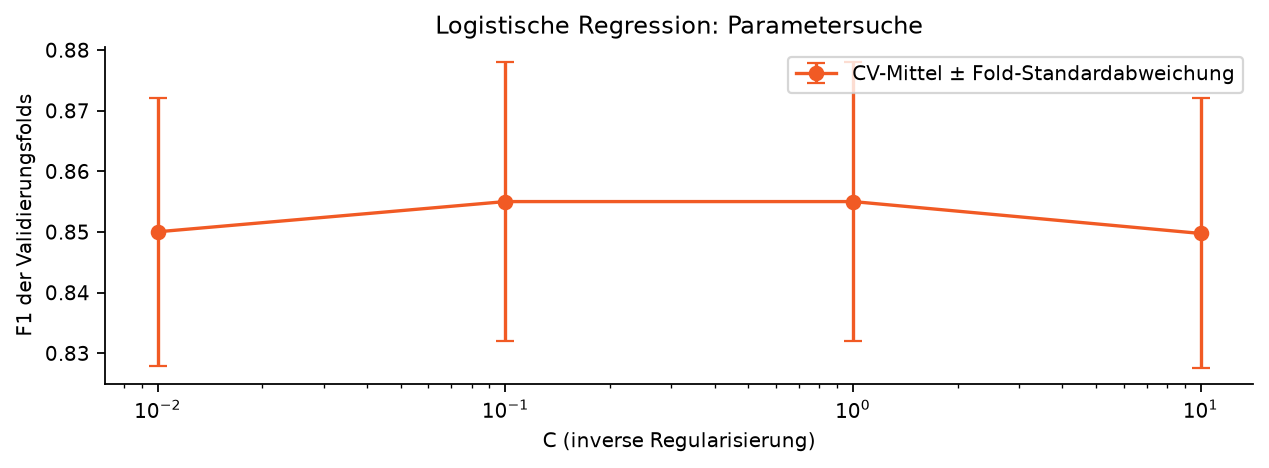

In [17]:

result_vis = pd.DataFrame(suche.cv_results_)
c_vis = result_vis["param_clf__C"].astype(float)
fig, ax = plt.subplots(figsize=(8, 3))
ax.errorbar(c_vis, result_vis.mean_test_score,
    yerr=result_vis.std_test_score, marker="o", capsize=4,
    color="#f15a24", label="CV-Mittel ± Fold-Standardabweichung")
ax.set(xscale="log", xlabel="C (inverse Regularisierung)",
       ylabel="F1 der Validierungsfolds", title="Logistische Regression: Parametersuche")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

**Bild lesen**

Großes C bedeutet schwächere Regularisierung. Überlappende Fehlerbalken erinnern daran, dass winzige Unterschiede im Mittelwert keine eindeutige praktische Überlegenheit belegen.

**Nächster Schritt**

Bei ähnlicher Leistung ein einfacheres oder stabileres Modell erwägen. Die Parameterauswahl bleibt in der CV; ein endgültiger Testwert darf nicht zur nachträglichen Feinabstimmung verwendet werden.

## 18 Seltene Klassen und Schwellen

Bei seltenen Fehlern kann ein Modell mit hoher Accuracy fast alle wichtigen Fälle übersehen. Klassenweights, Sampling und ein passender Entscheidungsschwellenwert beantworten unterschiedliche Probleme.

**Merksatz:** Sampling ausschließlich im Trainingsfold. Schwellen an Validierungsdaten wählen und anschließend für den finalen Test festhalten.

Kursbezug: Set 4: 06_klassenungleichgewicht_und_smote.ipynb

In [18]:

from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold
from imblearn.pipeline import Pipeline as SamplingPipeline
from imblearn.over_sampling import SMOTE
Xi, yi = make_classification(n_samples=1000, n_features=8,
    n_informative=4, weights=[.95, .05], random_state=42)
a, b, c, d = train_test_split(Xi, yi, stratify=yi,
                             test_size=.25, random_state=42)
balanced = SamplingPipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("sample", SMOTE(random_state=42, k_neighbors=3)),
    ("clf", LogisticRegression(max_iter=2000))])
cv = StratifiedKFold(5, shuffle=True, random_state=42)
scores = cross_validate(balanced, a, c, cv=cv,
    scoring=["recall", "precision", "average_precision"])
print({k: round(v.mean(), 3) for k, v in scores.items()
       if k.startswith("test_")})
plt.show()

{'test_recall': np.float64(0.594), 'test_precision': np.float64(0.109), 'test_average_precision': np.float64(0.196)}


**Gewichtung als Alternative**

LogisticRegression(class_weight="balanced") verändert die Gewichtung im Verlust. Es entstehen keine neuen Zeilen. Gewichtung und SMOTE separat innerhalb derselben CV vergleichen; automatisch kombinieren muss nicht besser sein.

**SMOTE hat Voraussetzungen**

Es interpoliert zwischen Nachbarn. Kategoriale Werte brauchen beispielsweise SMOTENC; One-Hot-Interpolation kann unsinnige Zwischenwerte erzeugen. Auch genügend Minderheitsbeispiele pro Fold und die Gruppenstruktur beachten.

**Schwelle und Kalibrierung**

p >= 0.5 ist nur eine Regel. Auf Validierung etwa einen Mindest-Recall verlangen und dann Precision bzw. Kosten vergleichen. Sampling und Klassenweights können Wahrscheinlichkeiten verschieben; Kalibrierung bei Bedarf separat validieren.

## 19 Regressionsmetriken und Plots

MAE beschreibt den mittleren absoluten Fehler in der Zieleinheit. RMSE gewichtet große Fehler stärker; R² beschreibt die Verbesserung gegenüber einem konstanten Mittelwert auf den ausgewerteten Daten.

**Merksatz:** Ein kleiner Trainingsfehler ist keine Generalisierung. Auf zurückgehaltenen Daten mit einer einfachen Baseline vergleichen und die Residuen ansehen.

Kursbezug: Set 5: 01_lineare_regression.ipynb; Set 10: 02_svm_regression.ipynb

MAE: 67.32
RMSE: 81.92
R2: 0.912
Baseline-MAE: 248.56


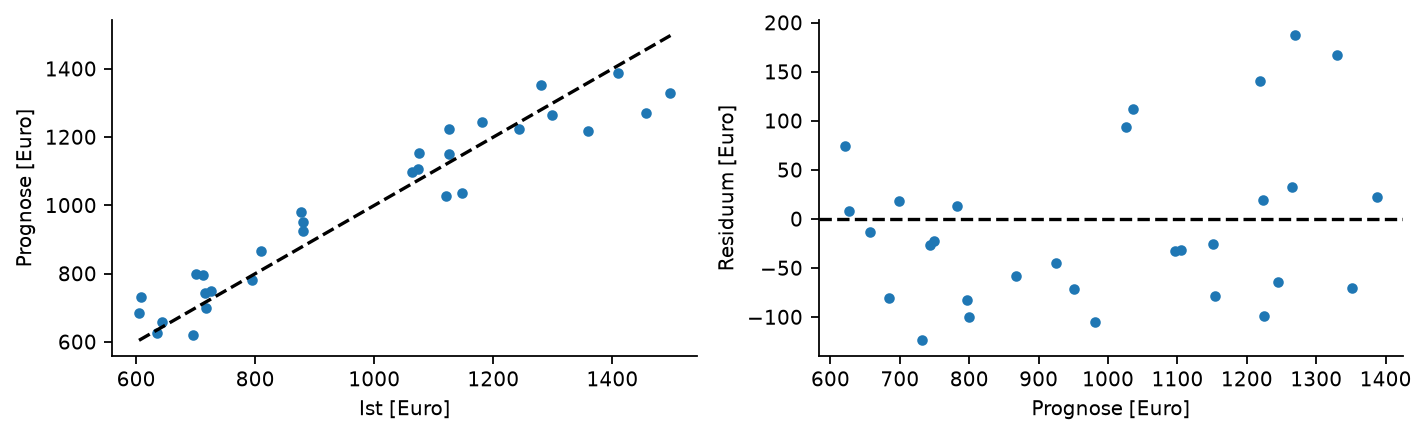

In [19]:

from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
reg = LinearRegression().fit(Xrt, yrt)
pred_r = reg.predict(Xre)
baseline = DummyRegressor().fit(Xrt, yrt).predict(Xre)
print("MAE:", round(mean_absolute_error(yre, pred_r), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(yre, pred_r)), 2))
print("R2:", round(r2_score(yre, pred_r), 3))
print("Baseline-MAE:", round(mean_absolute_error(yre, baseline), 2))
fig, ax = plt.subplots(1, 2, figsize=(9, 2.8))
ax[0].scatter(yre, pred_r, s=14)
lo, hi = min(yre.min(), pred_r.min()), max(yre.max(), pred_r.max())
ax[0].plot([lo, hi], [lo, hi], "k--")
ax[0].set(xlabel="Ist [Euro]", ylabel="Prognose [Euro]")
ax[1].scatter(pred_r, yre-pred_r, s=14)
ax[1].axhline(0, color="black", ls="--")
ax[1].set(xlabel="Prognose [Euro]", ylabel="Residuum [Euro]")
fig.tight_layout()
plt.show()

**Interpretation**

R² = 1 ist perfekt, R² = 0 entspricht auf diesen Testdaten dem Testmittelwert, R² < 0 ist schlechter. Der DummyRegressor verwendet dagegen den Trainingsmittelwert. R² ist kein Prozentwert korrekter Vorhersagen.

**Was im Plot auffällt**

Eine Kurve in den Residuen deutet auf fehlende Nichtlinearität, eine Trichterform auf veränderliche Streuung. Zeitlich korrelierte Residuen sprechen für noch nicht erfasste Dynamik. MAPE ist bei nullnahen Zielen problematisch.

## 20 Klassifikationsmetriken und Plots

Precision fragt, wie viele positive Meldungen stimmen; Recall, wie viele echte positive Fälle gefunden werden. F1 verbindet beide, während ROC-AUC und Average Precision kontinuierliche Scores auswerten.

**Merksatz:** Positive Klasse ausdrücklich festlegen. Bei Multiclass macro-F1 für die gleichgewichtete Sicht auf Klassen verwenden und Klassen einzeln prüfen.

Kursbezug: Set 5: 03_logistische_regression.ipynb; Set 4: 06_klassenungleichgewicht_und_smote.ipynb

              precision    recall  f1-score   support

           0      0.955     1.000     0.977        63
           1      1.000     0.952     0.975        62

    accuracy                          0.976       125
   macro avg      0.977     0.976     0.976       125
weighted avg      0.977     0.976     0.976       125

ROC-AUC: 0.996 AP: 0.996


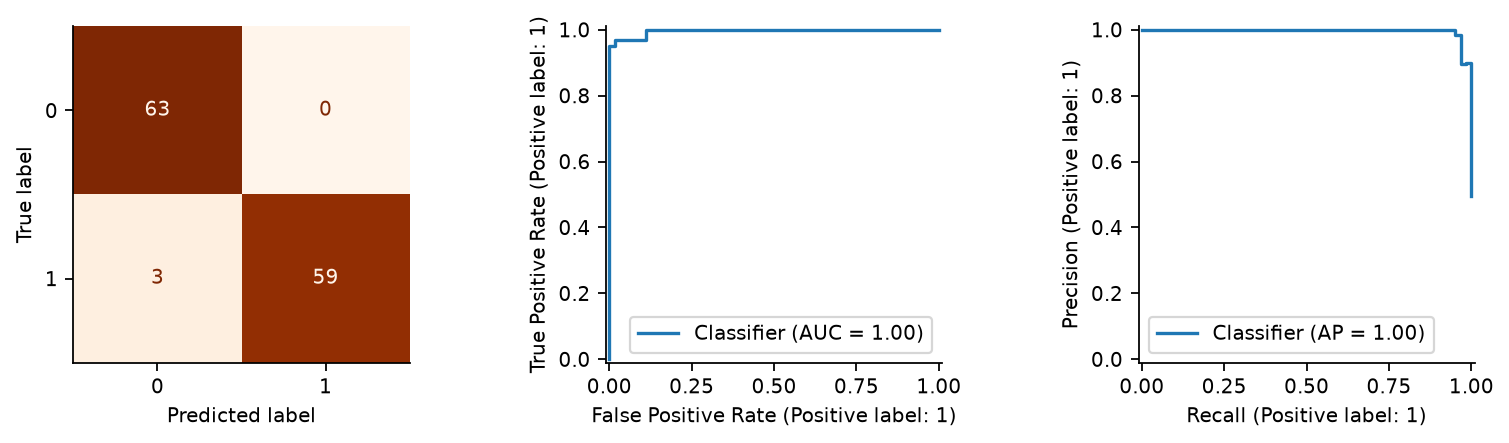

In [20]:

from sklearn.svm import SVC
from sklearn.metrics import (classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay, roc_auc_score, average_precision_score)
clf = make_pipeline(StandardScaler(), SVC(C=1, kernel="rbf"))
clf.fit(Xct, yct)
pred_c = clf.predict(Xce)
score_c = clf.decision_function(Xce)  # Klasse 1 ist positiv
print(classification_report(yce, pred_c, zero_division=0, digits=3))
print("ROC-AUC:", round(roc_auc_score(yce, score_c), 3),
      "AP:", round(average_precision_score(yce, score_c), 3))
fig, ax = plt.subplots(1, 3, figsize=(10, 2.8))
ConfusionMatrixDisplay.from_predictions(yce, pred_c, ax=ax[0],
    colorbar=False, cmap="Oranges")
RocCurveDisplay.from_predictions(yce, score_c, ax=ax[1])
PrecisionRecallDisplay.from_predictions(yce, score_c, ax=ax[2])
fig.tight_layout()
plt.show()

**Formeln**

Precision = TP/(TP+FP), Recall = TP/(TP+FN), F1 = 2PR/(P+R). In der sklearn-Konfusionsmatrix sind Zeilen die echten Klassen und Spalten die Vorhersagen. Balanced Accuracy mittelt den Recall über die Klassen.

**Seltene Klasse**

Accuracy kann irreführen. PR-Kurve und AP ergänzen, Prävalenz nennen und die Kosten von FP/FN diskutieren. AP und ROC-AUC sind keine Kennzahlen eines einzelnen Schwellenwerts; AP ist nicht einfach die trapezförmige Fläche unter jedem PR-Plot.

**Multiclass und Wahrscheinlichkeiten**

classification_report zeigt Klassen und macro/weighted-Mittel. ROC/PR erfordern z. B. eine One-vs-Rest-Auswertung. Für log_loss oder Kalibrierung echte Wahrscheinlichkeiten verwenden; SVM-Decision-Scores sind keine Wahrscheinlichkeiten.

## 21 Lineare Regression

LinearRegression schätzt einen additiven Zusammenhang zwischen Merkmalen und einer Zahl. Sie liefert eine schnelle Baseline und gut nachvollziehbare Koeffizienten.

**Merksatz:** Ein Koeffizient beschreibt den geschätzten Zusammenhang bei konstanten anderen Merkmalen. Das ist ohne kausales Studiendesign kein Beweis für eine Ursache.

Kursbezug: Set 5: 01_lineare_regression.ipynb; 05_xai_koeffizienten.ipynb

Miete = 8.29 * Fläche + 337.67
80 m²: 1000.7 Euro
Test-R2: 0.912


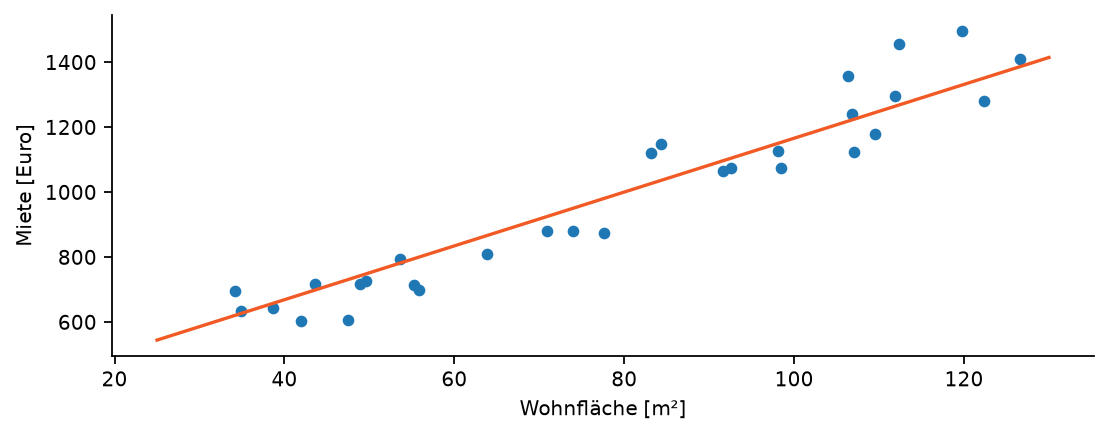

In [21]:

from sklearn.linear_model import LinearRegression
linear = LinearRegression().fit(Xrt, yrt)
m, b = linear.coef_[0], linear.intercept_
neu = pd.DataFrame({"flaeche_qm": [80.]})
print(f"Miete = {m:.2f} * Fläche + {b:.2f}")
print("80 m²:", round(linear.predict(neu)[0], 2), "Euro")
print("Test-R2:", round(linear.score(Xre, yre), 3))
grid = pd.DataFrame({"flaeche_qm": np.linspace(25, 130, 100)})
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.scatter(Xre.iloc[:, 0], yre, s=18, label="Test")
ax.plot(grid.iloc[:, 0], linear.predict(grid), color="#f15a24")
ax.set(xlabel="Wohnfläche [m²]", ylabel="Miete [Euro]")
fig.tight_layout()
plt.show()

**Ergebnis im Kurs**

Für genau die gerundeten Mietdaten aus Set 5: Steigung 8,29 Euro/m², Achsenabschnitt 337,67 Euro, Vorhersage für 80 m² rund 1000,70 Euro. Die Regressionsmetriken stehen auf Seite 19.

**Nichtlinear über Features**

PolynomialFeatures(degree=2, include_bias=False) ergänzt Quadrate und Wechselwirkungen. Das Modell bleibt linear in den Koeffizienten, kann aber gekrümmte Verläufe abbilden. Grad und Regularisierung innerhalb der CV wählen.

**Grenzen**

Korrelation zwischen Merkmalen macht einzelne Koeffizienten instabil. Extrapolation außerhalb des Trainingsbereichs kann trotz guter Testgüte scheitern.

## 22 Logistische Regression

LogisticRegression modelliert Klassenwahrscheinlichkeiten; der Name bezeichnet ein Klassifikationsverfahren. Für binäre Ziele ist der Logit der positiven Wahrscheinlichkeit linear in den Merkmalen.

**Merksatz:** predict_proba liefert Wahrscheinlichkeiten in der Reihenfolge classes_. Der Entscheidungsschwellenwert ist eine zusätzliche fachliche Wahl.

Kursbezug: Set 5: 03_logistische_regression.ipynb; 04_pipeline_palmer_penguins.ipynb

In [22]:

from sklearn.linear_model import LogisticRegression
logistic = make_pipeline(StandardScaler(),
    LogisticRegression(C=1, max_iter=2000))
logistic.fit(Xct, yct)
classes = logistic[-1].classes_
pos = list(classes).index(1)
p = logistic.predict_proba(Xce)[:, pos]
pred = (p >= .5).astype(int)
print("Klassen:", classes)
print("Erste Wahrscheinlichkeiten:", np.round(p[:5], 3))
print("Test-F1:", round(f1_score(yce, pred), 3))
print("Gewichte:", np.round(logistic[-1].coef_, 3))
plt.show()

Klassen: [0 1]
Erste Wahrscheinlichkeiten: [0.714 0.088 0.234 0.937 0.121]
Test-F1: 0.852
Gewichte: [[ 1.05  -2.482]]


**Was bedeutet C?**

C ist die inverse Regularisierungsstärke: kleineres C bedeutet stärkere Regularisierung. Standardmäßig wird L2-Regularisierung eingesetzt. Eingaben skalieren und C innerhalb der CV auswählen.

**Gerade Grenzen**

Auf Halbmond-Daten kann eine lineare Entscheidungsgrenze unterpassen. Eine RBF-SVM oder fachlich sinnvolle nichtlineare Features können besser passen; dafür muss die Bewertung gleich aufgebaut sein.

**Koeffizienten**

Ein positives binäres Gewicht erhöht den Logit von classes_[1]. exp(Gewicht) ist der Faktor für die Odds bei einer Merkmalseinheit mehr. Bei standardisierten Merkmalen entspricht eine Einheit einer Trainingsstandardabweichung; korrelierte Features erschweren die Interpretation.

## 23 Regularisierung mit Ridge und Lasso

Regularisierung begrenzt die Komplexität: Ridge schrumpft Gewichte mit einer L2-Strafe, Lasso kann mit einer L1-Strafe Gewichte exakt auf null setzen. ElasticNet verbindet beide.

**Merksatz:** Bei Ridge/Lasso bedeutet größeres alpha stärkere Regularisierung. Skalierung und die Wahl von alpha gehören in dieselbe Pipeline und CV.

Kursbezug: Set 6: 02_regularisierung_l1_l2.ipynb; 03_hyperparameter_tuning_regression.ipynb

In [23]:

from sklearn.datasets import make_regression
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV, KFold
X, y = make_regression(n_samples=60, n_features=30,
    n_informative=5, noise=20, random_state=42)
a, b, c, d = train_test_split(X, y, test_size=.3, random_state=42)
pipe = Pipeline([("scale", StandardScaler()), ("reg", Ridge())])
cv = KFold(5, shuffle=True, random_state=42)
grid = [{"reg": [Ridge()], "reg__alpha": [.1, 1, 10, 100]},
        {"reg": [Lasso(max_iter=20000)],
         "reg__alpha": [.1, 1, 10]}]
search = GridSearchCV(pipe, grid, cv=cv,
    scoring="neg_root_mean_squared_error")
search.fit(a, c)
pred = search.predict(b)
print("Gewählt:", search.best_params_)
print("Test-RMSE:", round(np.sqrt(mean_squared_error(d, pred)), 2))
print("Gewichte != 0:",
      np.count_nonzero(search.best_estimator_[-1].coef_))
plt.show()

Gewählt: {'reg': Lasso(max_iter=20000), 'reg__alpha': 1}
Test-RMSE: 29.88
Gewichte != 0: 21


**Bias und Varianz**

Sehr flexible Modelle können Trainingsrauschen lernen. Stärkere Regularisierung erhöht oft den Bias und senkt die Varianz. Ein wachsender Abstand zwischen Trainings- und Validierungsfehler ist ein Warnsignal für Overfitting.

**Lasso und ElasticNet**

Lasso-Selektion kann bei stark korrelierten Merkmalen zwischen ähnlichen Variablen wechseln. ElasticNet(alpha=..., l1_ratio=...) mischt L1 und L2; l1_ratio nahe 1 verhält sich stärker wie Lasso. Nullgewichte sind kein Beweis fachlicher Irrelevanz.

## 24 Regularisierung an Gewichten erkennen

Koeffizientenplots zeigen, wie Ridge alle Gewichte schrumpft und Lasso viele Gewichte auf null setzt. Standardisierte Eingaben machen die Größen im Vergleich besser lesbar.

**Merksatz:** Weniger große Koeffizienten können Overfitting reduzieren. Ein auf null gesetztes Gewicht ist keine allgemeine Aussage über die Bedeutung einer Messgröße.

Kursbezug: Set 6: 02_regularisierung_l1_l2.ipynb

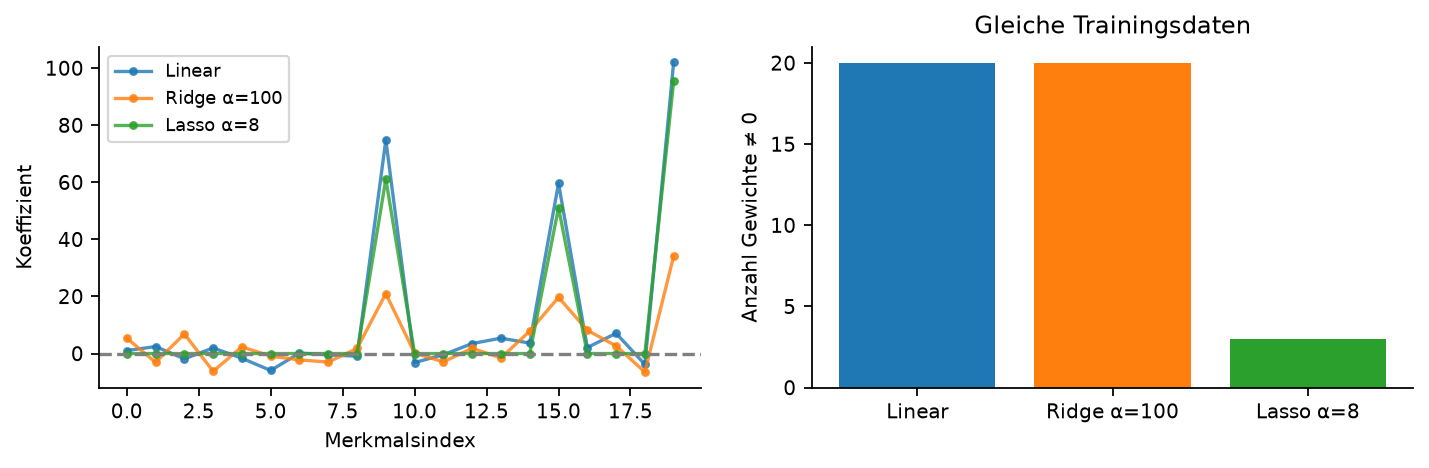

In [24]:

from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso
xv, yv = make_regression(n_samples=60, n_features=20,
    n_informative=4, noise=25, random_state=42)
xv = StandardScaler().fit_transform(xv)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for name, est in [("Linear",LinearRegression()),
                   ("Ridge α=100",Ridge(alpha=100)),
                   ("Lasso α=8",Lasso(alpha=8, max_iter=20000))]:
    est.fit(xv, yv)
    ax[0].plot(est.coef_, ".-", label=name, alpha=.8)
    ax[1].bar(name, np.count_nonzero(np.abs(est.coef_)>1e-8))
ax[0].set(xlabel="Merkmalsindex", ylabel="Koeffizient")
ax[0].axhline(0, color="grey", ls="--"); ax[0].legend(fontsize=8)
ax[1].set(ylabel="Anzahl Gewichte ≠ 0", title="Gleiche Trainingsdaten")
fig.tight_layout()
plt.show()

**Bild lesen**

Ridge verkleinert die Gewichte, lässt sie typischerweise aber ungleich null. Lasso entfernt bei dieser Stärke viele schwache Koeffizienten vollständig. Die α-Werte der Verfahren sind keine direkt gleichwertigen Skalen.

**Keine Bewertung im Trainingsplot**

Hier werden die Effekte auf denselben Trainingsdaten demonstriert. Die Abbildung berichtet keine Testgüte. Welche Regularisierung am besten generalisiert, wird mit einer Pipeline in CV bestimmt.

## 25 Naive Bayes und Textmerkmale

Naive Bayes ist eine schnelle probabilistische Baseline mit bedingter Unabhängigkeitsannahme. GaussianNB passt zu kontinuierlichen Merkmalen, MultinomialNB zu nichtnegativen Zählmerkmalen wie Wortanzahlen.

**Merksatz:** Der Textvektorisierer lernt sein Vokabular nur am Training. StandardScaler mit Zentrierung passt nicht vor MultinomialNB, weil negative Werte entstehen können.

Kursbezug: Set 7: 01_gaussian_naive_bayes.ipynb; 03_textmerkmale_multinomial_naive_bayes.ipynb

In [25]:

from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer
nb = GaussianNB().fit(Xct, yct)
print("GaussianNB F1:", round(f1_score(yce, nb.predict(Xce)), 3))
path = ROOT / "set7-naive-bayes-und-textklassifikation/daten"
sms = pd.read_csv(path / "SMSSpamCollection", sep="	",
                  header=None, names=["label", "text"])
a, b, c, d = train_test_split(sms.text, sms.label,
    stratify=sms.label, test_size=.25, random_state=42)
spam = make_pipeline(CountVectorizer(), MultinomialNB(alpha=1))
spam.fit(a, c)
pred = spam.predict(b)
print("Spam-F1:", round(f1_score(d, pred, pos_label="spam"), 3))
print("Vokabular:", len(spam[0].vocabulary_))
plt.show()

GaussianNB F1: 0.839
Spam-F1: 0.947
Vokabular: 7387


**Wofür die Varianten gut sind**

GaussianNB modelliert pro Klasse und Merkmal eine Normalverteilung. MultinomialNB nutzt nichtnegative Häufigkeiten; BernoulliNB modelliert binäre Merkmalspräsenz. Keine dieser Annahmen ist automatisch durch den Namen des Datensatzes erfüllt.

**Glättung und Bewertung**

alpha verhindert Nullwahrscheinlichkeiten für ungesehene Wörter. Für Spam Precision und Recall der Klasse spam prüfen. Naive-Bayes-Wahrscheinlichkeiten können überkonfident sein, obwohl die Klassenentscheidung nützlich ist.

**Wiederholte Nachrichten**

Duplikate, Sendergruppen und zeitliche Änderungen können Zufallssplits zu optimistisch machen. Der kleine Kursvergleich ist ein Einstieg; für die reale Anwendung entsprechend splitten.

## 26 Entscheidungsbäume und Ensembles

Ein Entscheidungsbaum bildet nichtlineare Wenn-dann-Regeln. Random Forest mittelt viele zufällig variierte Bäume; Gradient Boosting ergänzt schrittweise Bäume zur Fehlerkorrektur.

**Merksatz:** Bäume benötigen normalerweise keine Skalierung. Tiefe, Mindestblattgröße und bei Ensembles Lernrate bzw. Anzahl der Bäume steuern die Komplexität.

Kursbezug: Set 8: 01_entscheidungsbaum_klassifikation.ipynb bis 04_gradient_boosting_und_modellvergleich.ipynb

In [26]:

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
models = {
    "Baum": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Forest": RandomForestClassifier(n_estimators=200,
        min_samples_leaf=2, random_state=42),
    "Boosting": GradientBoostingClassifier(n_estimators=100,
        learning_rate=.05, max_depth=2, random_state=42)}
for name, model in models.items():
    model.fit(Xct, yct)
    print(name, "F1:", round(f1_score(yce, model.predict(Xce)), 3))
tree_r = DecisionTreeRegressor(max_depth=3, min_samples_leaf=5,
                               random_state=42).fit(Xrt, yrt)
print("Regressionsbaum-MAE:",
      round(mean_absolute_error(yre, tree_r.predict(Xre)), 2))
plt.show()

Baum F1: 0.896
Forest F1: 0.942
Boosting F1: 0.95
Regressionsbaum-MAE: 68.46


**Klassifikation und Regression**

Klassifikationsbäume reduzieren typischerweise Gini-Unreinheit oder Entropie, Regressionsbäume die Streuung der Zielwerte. Regressionsbäume liefern stückweise konstante Vorhersagen und extrapolieren Trends schlecht.

**Regeln visualisieren**

from sklearn.tree import plot_tree; plot_tree(models["Baum"], max_depth=2, feature_names=["x1", "x2"], filled=True). Die Begrenzung im Plot kürzt nur die Anzeige, nicht das trainierte Modell.

**Kein Sieger aus diesem Einzeltest**

Die drei festen Konfigurationen illustrieren unterschiedliche Verfahren. Für eine Modellauswahl dieselben CV-Splits und Suchbudgets verwenden; danach den reservierten Test einmal auswerten. Impurity-Importances können hochkardinale Merkmale bevorzugen.

## 27 Entscheidungsregeln als Baum

Ein Baumdiagramm zeigt die nacheinander verwendeten Schwellen. An jedem Knoten wird eine Zeile nach links oder rechts weitergeleitet, bis ein Blatt eine Klasse liefert.

**Merksatz:** Eine lesbare Baumgrafik ist eine Darstellung des Modells. Die fachliche Plausibilität seiner Regeln und die Leistung auf neuen Daten müssen separat geprüft werden.

Kursbezug: Set 8: 01_entscheidungsbaum_klassifikation.ipynb

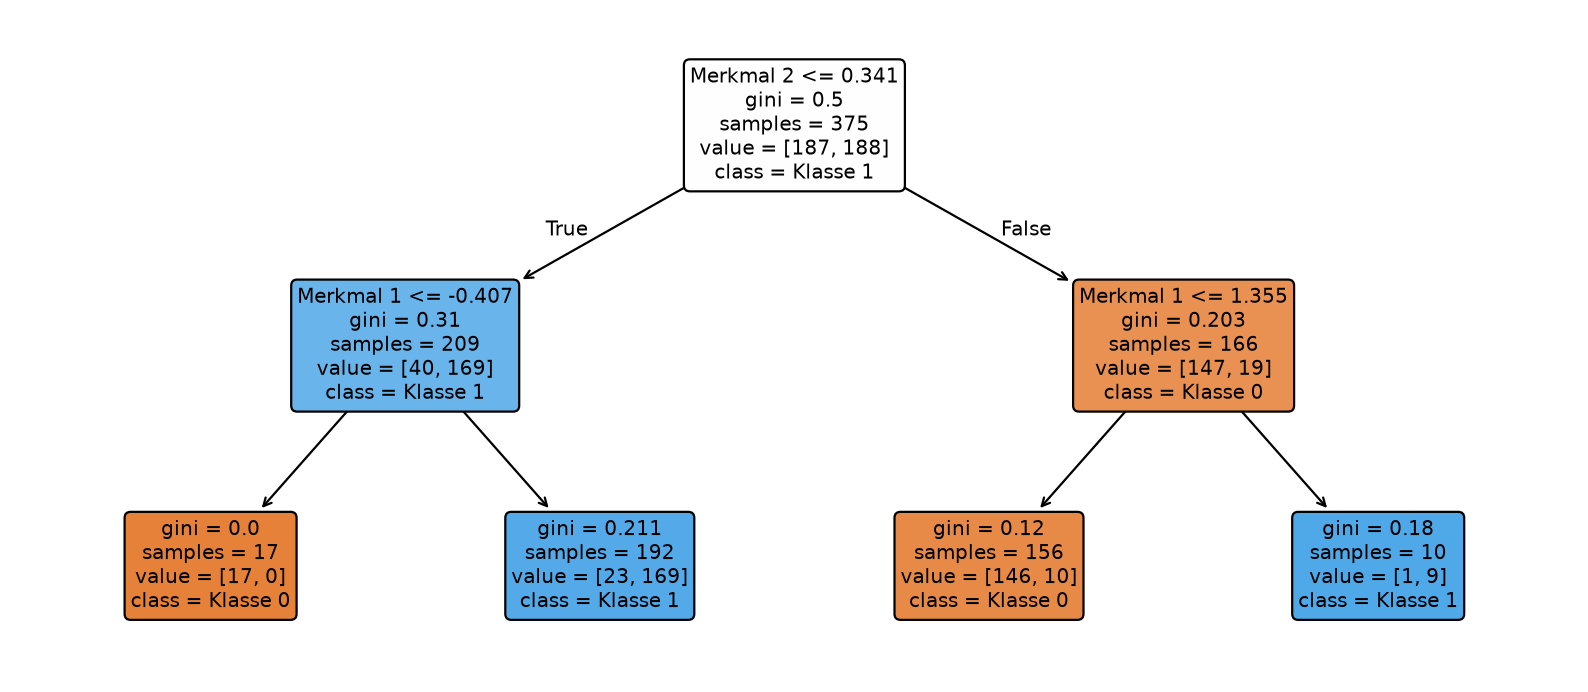

In [27]:

from sklearn.tree import DecisionTreeClassifier, plot_tree
vis_tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=10,
                                   random_state=42).fit(Xct, yct)
fig, ax = plt.subplots(figsize=(10, 4.4))
plot_tree(vis_tree, feature_names=["Merkmal 1", "Merkmal 2"],
    class_names=["Klasse 0", "Klasse 1"], filled=True,
    rounded=True, impurity=True, proportion=False,
    fontsize=9, ax=ax)
fig.tight_layout()
plt.show()

**Knoten lesen**

Die erste Zeile zeigt die Splitbedingung. Die erfüllte Bedingung führt nach links. samples zählt Trainingsbeispiele, value enthält die Klassenverteilung, class die Mehrheitsklasse. Je nach sklearn-Version kann value Anteile statt absoluter Zahlen anzeigen.

**Unreinheit und Tiefe**

Gini nahe 0 bedeutet im Training fast nur eine Klasse in diesem Knoten. Tiefe Bäume können sehr reine Blätter mit wenigen Beispielen erzeugen und trotzdem schlecht generalisieren. Die hier gewählte Tiefe 2 hält die gesamte Grafik lesbar.

## 28 SVM und nächste Nachbarn

SVM sucht eine trennende Grenze mit kontrollierter Marge; mit RBF-Kernel auch nichtlinear. kNN entscheidet anhand ähnlicher Trainingspunkte und ist eine anschauliche lokale Baseline.

**Merksatz:** Beide reagieren auf Merkmalsabstände. Skalierung gehört davor in die Pipeline; irrelevante Dimensionen können Nachbarschaften unbrauchbar machen.

Kursbezug: Set 9: 01_knn_pipeline_klassifikation.ipynb, 03_distanzen_gewichtung_und_regression.ipynb; Set 10: 01/02

In [28]:

from sklearn.svm import SVC, SVR
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
for name, estimator in [
    ("SVM", SVC(C=1, gamma="scale", kernel="rbf")),
    ("kNN", KNeighborsClassifier(n_neighbors=7, weights="distance"))]:
    model = make_pipeline(StandardScaler(), estimator).fit(Xct, yct)
    print(name, "F1:", round(f1_score(yce, model.predict(Xce)), 3))
for name, estimator in [
    ("SVR", SVR(C=500, epsilon=20)),
    ("kNN-Reg", KNeighborsRegressor(n_neighbors=7,
                                    weights="distance"))]:
    model = make_pipeline(StandardScaler(), estimator).fit(Xrt, yrt)
    print(name, "MAE:",
          round(mean_absolute_error(yre, model.predict(Xre)), 2))
plt.show()

SVM F1: 0.975
kNN F1: 0.943
SVR MAE: 63.43
kNN-Reg MAE: 78.79


**SVM-Parameter**

Größeres C bestraft Trainingsverletzungen stärker. Größeres gamma macht die RBF-Wirkung lokaler und kann überfitten. SVR ignoriert Fehler innerhalb des epsilon-Schlauchs; epsilon wird in Zieleinheiten angegeben. Decision-Scores sind keine Wahrscheinlichkeiten.

**kNN-Parameter**

Kleines k reagiert stärker auf Rauschen; großes k glättet. weights="distance" gewichtet nahe Punkte stärker. Für Minkowski-Distanz liefert p=1 Manhattan und p=2 Euklidisch. PCA oder Feature-Auswahl nur innerhalb der CV fitten.

**Kursresultat**

Die SVM-Konfiguration auf den identischen Halbmond-Daten aus Set 10 liefert im gespeicherten Kurslauf Accuracy 0,976 und F1 0,975. Das ist die feste Ausgangskonfiguration vor der dortigen Parametersuche.

## 29 Entscheidungsgrenzen im Vergleich

Entscheidungsflächen zeigen, welche Klasse ein Modell an jeder Position des Merkmalsraums vorhersagt. Darübergelegte Trainingspunkte machen Unteranpassung und lokale Grenzformen sichtbar.

**Merksatz:** Diese Grafik funktioniert hier, weil das Modell genau zwei Eingaben hat. Ein 2D-Ausschnitt aus vielen Dimensionen ist nur eine bedingte Ansicht.

Kursbezug: Sets 5, 8, 9 und 10: Klassifikationsnotebooks mit Entscheidungsgrenzen

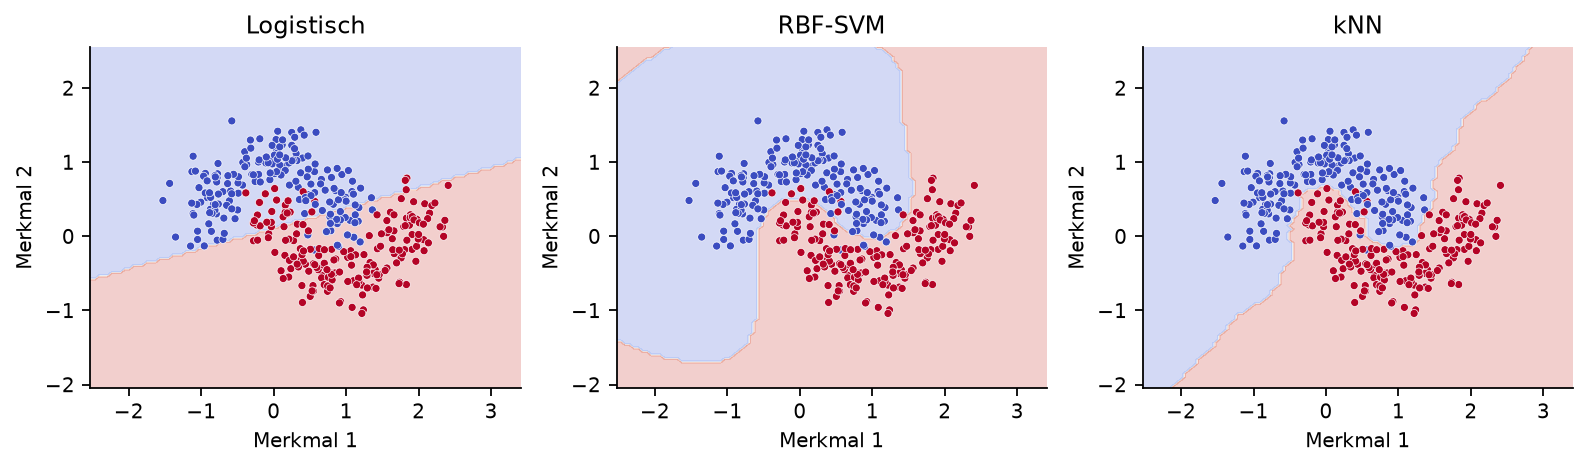

In [29]:

from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
fig, ax = plt.subplots(1, 3, figsize=(10, 3))
estimators_vis = [LogisticRegression(), SVC(C=1, kernel="rbf"),
                  KNeighborsClassifier(7, weights="distance")]
for a, est, name in zip(ax, estimators_vis, ["Logistisch", "RBF-SVM", "kNN"]):
    m_vis = make_pipeline(StandardScaler(), est).fit(Xct, yct)
    DecisionBoundaryDisplay.from_estimator(m_vis, Xct,
        response_method="predict", ax=a, cmap="coolwarm", alpha=.25)
    a.scatter(Xct[:,0], Xct[:,1], c=yct, cmap="coolwarm",
               edgecolors="white", linewidths=.3, s=13)
    a.set(title=name, xlabel="Merkmal 1", ylabel="Merkmal 2")
fig.tight_layout()
plt.show()

**Bild lesen**

Die logistische Regression erzeugt hier eine gerade Grenze. Die RBF-SVM kann den Halbmondformen folgen. kNN reagiert stärker auf lokale Nachbarschaften und kann kleine Inseln bilden.

**Güte nicht aus Schönheit ableiten**

Glatt oder komplex ist allein kein Gütekriterium. Modellwahl und Parameter gehören in dieselben Trainings- und Validierungssplits. Die Punkte im Bild sind ausschließlich Trainingspunkte; Testmetriken stehen im Methodenrezept.

## 30 CRF für zusammenhängende Labels

Conditional Random Fields vergeben Labels für ganze Sequenzen, etwa Person, Ort oder sonstiges Wort. Übergänge zwischen Nachbarlabels ergänzen die lokalen Merkmals-Scores.

**Merksatz:** Viterbi findet die Sequenz mit dem höchsten Score. Forward berechnet die Normierung über alle Sequenzen; beides hat eine andere Aufgabe.

Kursbezug: Exkurs: exkurs-conditional-random-fields/01_crf_score_forward_viterbi.ipynb

In [30]:

# Kompakte Viterbi-Dekodierung, analog zum Kurs-Exkurs
labels = np.array(["PER", "LOC", "O"])
W = np.array([[1.4,-1,-1,-.5,0], [1,1.8,-1,-.5,-.2],
              [-.8,-.4,1.2,1.4,.5]])
A = np.array([[.4,-.6,.7],[-.5,.3,.6],[.2,1.1,.8]])
tokens = ["Anna", "lebt", "in", "Berlin"]
F = np.array([[float(w[0].isupper()),
    float(i>0 and tokens[i-1].lower()=="in"),
    float(w.lower() in {"lebt","wohnt","arbeitet"}),
    float(w.lower()=="in"), 1.] for i,w in enumerate(tokens)])
E = F @ W.T
delta, back = E[0].copy(), []
for e in E[1:]:
    kandidaten = delta[:, None] + A
    back.append(kandidaten.argmax(axis=0))
    delta = e + kandidaten.max(axis=0)
pfad = [int(delta.argmax())]
for bp in reversed(back):
    pfad.append(int(bp[pfad[-1]]))
print(list(zip(tokens, labels[pfad[::-1]].tolist())))
print("Sequenzscore:", round(float(delta.max()), 2))
plt.show()

[('Anna', 'PER'), ('lebt', 'O'), ('in', 'O'), ('Berlin', 'LOC')]
Sequenzscore: 10.2


**Was dieses Beispiel tut**

Die Gewichte W und A sind didaktisch vorgegeben, nicht trainiert. Der Kurs zeigt Sequenzscore, vollständige Aufzählung, Forward-Normierung und Viterbi. Das Rezept behauptet deshalb keine trainierte CRF-Qualität.

**Wahrscheinlichkeit**

P(y|x) = exp(Score(x,y) - log Z(x)). log Z wird numerisch stabil mit logsumexp berechnet. Hoher roher Score ist ohne Normierung keine Wahrscheinlichkeit.

**Wie bewerten?**

Nach kompletten Sätzen oder Dokumenten splitten. Token-F1 und bei Entitäten zusätzlich exakten Span-F1 berichten; ein fast richtiger Mehrwort-Ort kann tokenweise gut und auf Entitätsebene falsch sein.

## 31 Zeitreihen vorbereiten und verstehen

Zeitreihen enthalten Reihenfolge, Trend und häufig saisonale Muster. Resampling, rollende Statistiken sowie ACF/PACF helfen, diese Struktur vor dem Modellieren zu verstehen.

**Merksatz:** Jedes Merkmal muss zum Prognosezeitpunkt verfügbar sein. Ein gleitender Mittelwert mit zukünftigen Werten erzeugt für Prognosen Leakage.

Kursbezug: Set 12: 01_zeitreihen_darstellen_und_fenster_interaktiv.ipynb; 02_trend_saisonalitaet_und_autokorrelation.ipynb

Train/Test: 200 40
Letztes Trainingsdatum: 2025-07-19


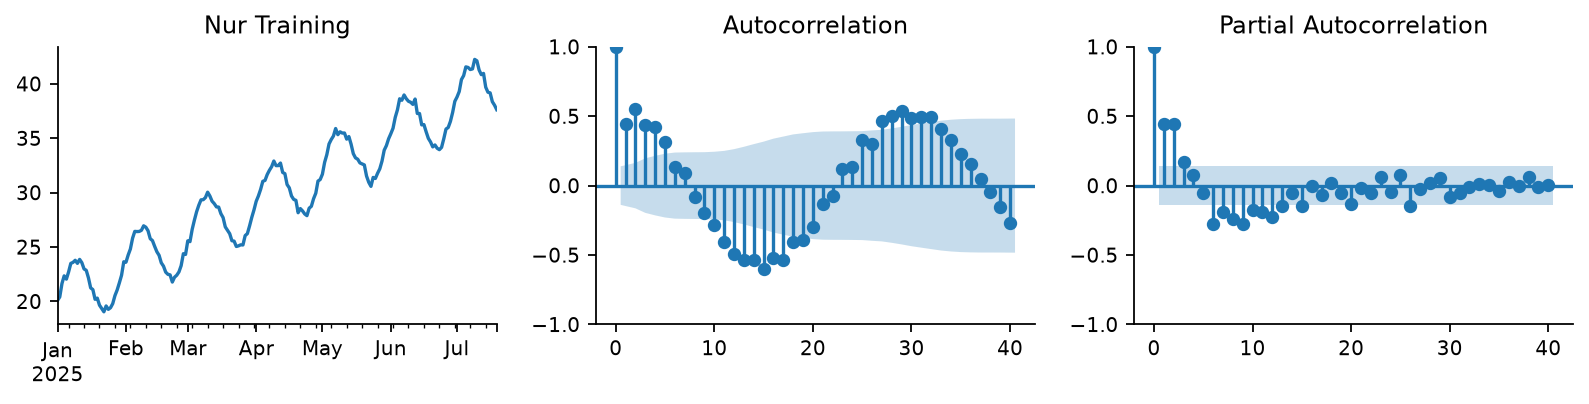

In [31]:

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
index = pd.date_range("2025-01-01", periods=240, freq="D")
rng = np.random.default_rng(42)
serie = pd.Series(20 + .1*np.arange(240)
    + 3*np.sin(2*np.pi*np.arange(240)/30)
    + rng.normal(0, .3, 240), index=index)
ts_train, ts_test = serie.iloc[:200], serie.iloc[200:]
print("Train/Test:", len(ts_train), len(ts_test))
print("Letztes Trainingsdatum:", ts_train.index[-1].date())
fig, ax = plt.subplots(1, 3, figsize=(10, 2.6))
ts_train.plot(ax=ax[0], title="Nur Training")
plot_acf(ts_train.diff().dropna(), lags=40, ax=ax[1])
plot_pacf(ts_train.diff().dropna(), lags=40, ax=ax[2], method="ywm")
fig.tight_layout()
# Vergangenheitsmerkmal für Prognose am Zeitpunkt t
roll = serie.shift(1).rolling(7, min_periods=7).mean()
plt.show()

**Resampling**

Set 12 Energie: pd.read_csv(..., parse_dates=["date"]).set_index("date").sort_index(). Danach rechts geschlossene Stundenintervalle mit label="right", closed="right": Appliances summieren, T1 und RH_1 mitteln, nur Stunden mit sechs Messungen verwenden.

**ACF und PACF**

ACF misst Korrelation mit verzögerten Werten; PACF die verbleibende lineare Korrelation nach Berücksichtigung kürzerer Lags. Bei stationären idealen AR(p)- bzw. MA(q)-Prozessen helfen Abbruchmuster als Heuristik, ersetzen aber keine Validierung.

**Stationarität**

Ein wachsender Mittelwert kann Differenzierung verlangen. Saisonalität bleibt nach einmaliger Differenzierung möglicherweise erhalten. Trend, Saison, fehlende Zeitpunkte und Messraster zuerst prüfen; Glättung ist keine neue unabhängige Messung.

## 32 Trend Glättung und Autokorrelation

Zeitverlauf und gleitender Mittelwert zeigen langsame und schnelle Anteile. ACF und PACF machen verzögerte Zusammenhänge sichtbar und helfen, Modellannahmen zu hinterfragen.

**Merksatz:** Die Diagnose verwendet nur die Trainingsperiode. Differenzierung kann Trend entfernen, aber saisonale Abhängigkeiten erhalten.

Kursbezug: Set 12: 02_trend_saisonalitaet_und_autokorrelation.ipynb

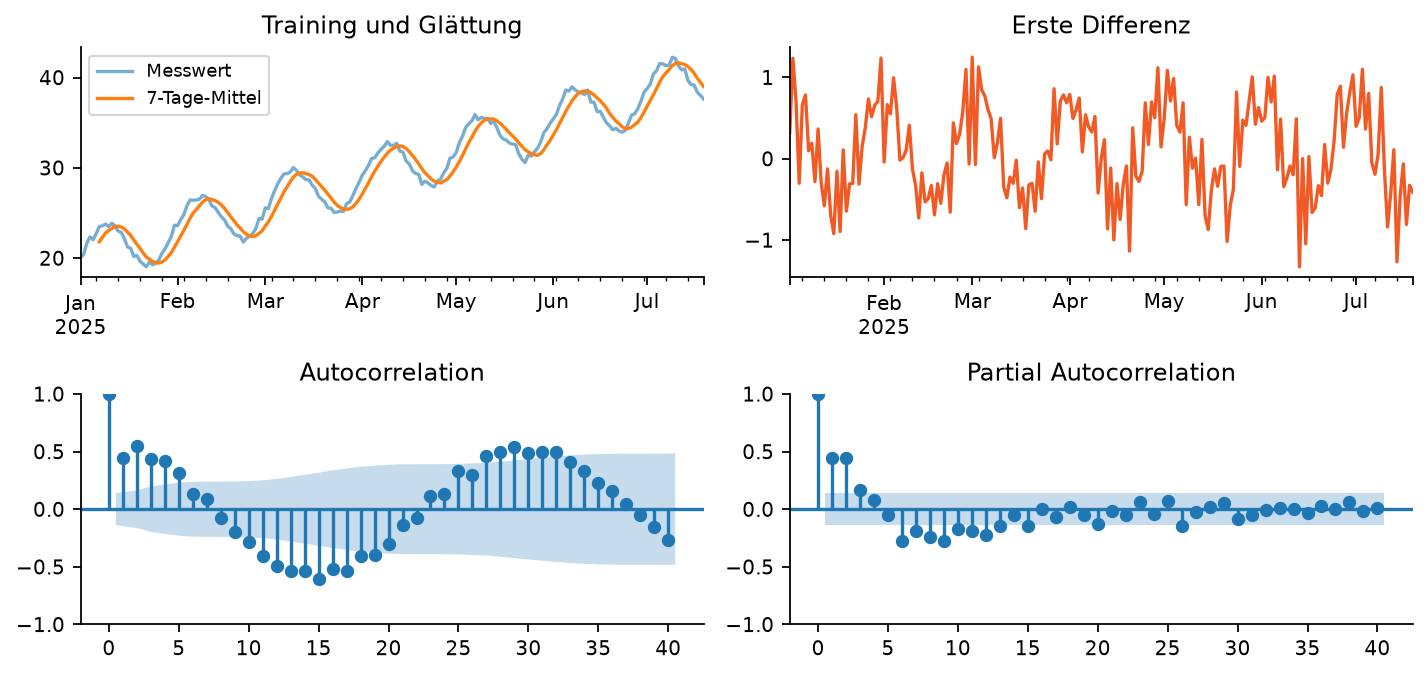

In [32]:

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, ax = plt.subplots(2, 2, figsize=(9, 4.3))
ts_train.plot(ax=ax[0,0], alpha=.6, label="Messwert")
ts_train.rolling(7).mean().plot(ax=ax[0,0], label="7-Tage-Mittel")
ax[0,0].legend(fontsize=8); ax[0,0].set_title("Training und Glättung")
diff_vis = ts_train.diff().dropna()
diff_vis.plot(ax=ax[0,1], color="#f15a24", title="Erste Differenz")
plot_acf(diff_vis, lags=40, ax=ax[1,0])
plot_pacf(diff_vis, lags=40, ax=ax[1,1], method="ywm")
fig.tight_layout()
plt.show()

**Bild lesen**

Der 7-Tage-Mittelwert glättet das Rauschen und folgt den langsameren Bewegungen. Die Differenzen schwanken um einen annähernd stabilen Mittelwert, zeigen aber weiterhin die periodische Dynamik.

**ACF und PACF**

Balken außerhalb des farbigen Bandes zeigen unter den jeweiligen Annahmen auffällige Lags. Die Bänder sind punktweise Näherungen, kein Beweis eines bestimmten ARIMA-Modells; viele getestete Lags und Saisonalität beachten.

## 33 AR MA ARMA und ARIMA

AR nutzt vergangene Reihenwerte, MA vergangene Innovationsfehler; ARMA kombiniert beide. ARIMA differenziert zusätzlich d-mal, um etwa einen Trend zu behandeln.

**Merksatz:** In statsmodels werden alle vier über ARIMA(order=(p,d,q)) formuliert. Ein MA(q)-Modell ist kein einfacher gleitender Mittelwert der beobachteten Werte.

Kursbezug: Set 12: 00_arma_arima_ganz_einfach.ipynb; 03b_ar_ma_und_arma.ipynb

ARIMA-MAE: 4.649
Naiv-MAE: 3.787


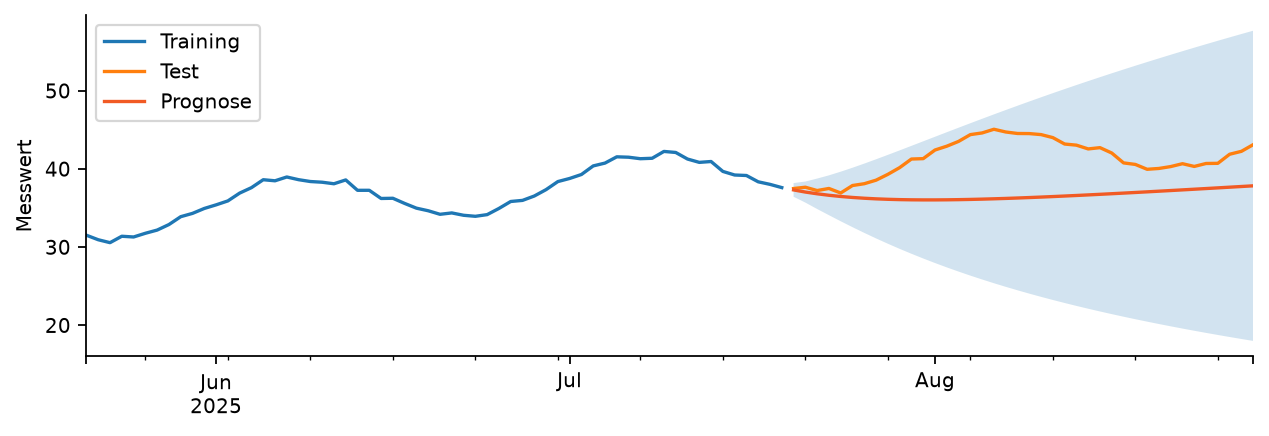

In [33]:

from statsmodels.tsa.arima.model import ARIMA
# Demo-Reihe von Seite 31; Parameter sind hier vorgegeben.
fit_ts = ARIMA(ts_train, order=(2, 1, 1), trend="t").fit()
forecast = fit_ts.get_forecast(steps=len(ts_test))
mean = forecast.predicted_mean
ci = forecast.conf_int(alpha=.05)
naive = np.repeat(ts_train.iloc[-1], len(ts_test))
print("ARIMA-MAE:", round(mean_absolute_error(ts_test, mean), 3))
print("Naiv-MAE:", round(mean_absolute_error(ts_test, naive), 3))
fig, ax = plt.subplots(figsize=(8, 2.8))
ts_train.iloc[-60:].plot(ax=ax, label="Training")
ts_test.plot(ax=ax, label="Test")
mean.plot(ax=ax, label="Prognose", color="#f15a24")
ax.fill_between(ci.index, ci.iloc[:,0], ci.iloc[:,1], alpha=.2)
ax.set(ylabel="Messwert"); ax.legend(); fig.tight_layout()
plt.show()

| Verfahren | order / Bedeutung |
| --- | --- |
| AR(p) | (p,0,0): lineare Abhängigkeit von p Vorwerten |
| MA(q) | (0,0,q): q vergangene Innovationsfehler |
| ARMA(p,q) | (p,0,q): Werte und Innovationsfehler |
| ARIMA(p,d,q) | (p,d,q): ARMA auf differenzierter Reihe |

**Trend und Unsicherheit**

Bei d=1 erlaubt trend="t" in dieser ARIMA-Formulierung einen Drift in der Originalreihe. Prognoseintervalle beruhen auf Modellannahmen; 95 % bedeutet keine garantierte Abdeckung bei Strukturbrüchen.

**Auswahl und Diagnostik**

p, d und q per Zeitvalidierung vergleichen. AIC/BIC nur für vergleichbare Fits ergänzend nutzen. Residuenplot und ACF prüfen. Für saisonale Dynamik seasonal_order=(P,D,Q,s) erwägen; ein tägliches Muster ist nicht durch d=1 erledigt.

## 34 Lags Backtesting und exogene Größen

Lag-Modelle machen aus der Zeitreihe eine überwachte Aufgabe. Backtesting wiederholt die Bewertung an historischen Prognoseursprüngen; exog ergänzt Größen, die für den Prognosehorizont bereits bekannt sind.

**Merksatz:** Eine feste 40-Tage-Prognose und täglich aktualisierte Ein-Schritt-Prognosen sind verschiedene Aufgaben. Den Horizont und die verfügbare Information immer nennen.

Kursbezug: Set 12: 03_zeitlicher_split_lags_und_backtesting.ipynb; 00_b und 00_c

In [34]:

from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import Ridge
tab = pd.DataFrame({"y": serie})
for lag in [1, 2, 7, 30]:
    tab[f"lag{lag}"] = serie.shift(lag)
tab = tab.dropna()
# Ein-Schritt-Backtest: vorherige echte Werte sind verfügbar.
dev = tab.loc[tab.index <= ts_train.index[-1]]
cv = TimeSeriesSplit(n_splits=3, test_size=20)
errors = []
for tr, va in cv.split(dev):
    m = make_pipeline(StandardScaler(), Ridge(alpha=1))
    m.fit(dev.iloc[tr].drop(columns="y"), dev.iloc[tr].y)
    p = m.predict(dev.iloc[va].drop(columns="y"))
    errors.append(mean_absolute_error(dev.iloc[va].y, p))
print("Fold-MAE:", np.round(errors, 3))
print("Mittlerer MAE:", round(np.mean(errors), 3))
plt.show()

Fold-MAE: [0.304 0.336 0.357]
Mittlerer MAE: 0.333


**Warum das kein fester Mehrschritt-Forecast ist**

Die Lag-Zeilen der Validierung enthalten jeweils zuvor beobachtete echte Werte. Das entspricht fortlaufend aktualisierten Ein-Schritt-Vorhersagen. Bei einem Forecast ohne neue Messwerte müssen Lags rekursiv mit Prognosen gefüllt oder direkte Horizontmodelle gelernt werden.

**Exogene Größen im Kurs**

ARIMA(training, order=(1,0,1), exog=merkmale_training).fit(); anschließend get_forecast(steps=H, exog=merkmale_zukunft). Ein Produktionsplan kann bekannt sein; das tatsächlich gemessene Wetter oder Sensorsignal von morgen normalerweise nicht.

**Schrittweise aktualisieren**

Erst forecast(steps=1, exog=naechste_merkmale), dann echten Wert beobachten, dann fit.append(neuer_wert, exog=naechste_merkmale, refit=False). append aktualisiert dabei den Zustand, ohne die Parameter neu zu schätzen. Bei h-Schritt-Zielen Trainingsgrenze und ggf. gap entsprechend absichern.

## 35 MLP für Tabellen und Regression

Ein Multi-Layer Perceptron lernt nichtlineare Merkmalskombinationen. MLPRegressor liefert Zahlen, MLPClassifier Klassen; mehrere versteckte Schichten bilden die Grundlage tiefer Netze.

**Merksatz:** Eingaben skalieren und Overfitting an Validierungsdaten beobachten. Early Stopping beendet das Training, wenn die Validierung nicht mehr besser wird.

Kursbezug: Set 13: 01_mlp_regression.ipynb; 02_mlp_klassifikation.ipynb

MAE: 0.186 R2: 0.947
Epochen: 136


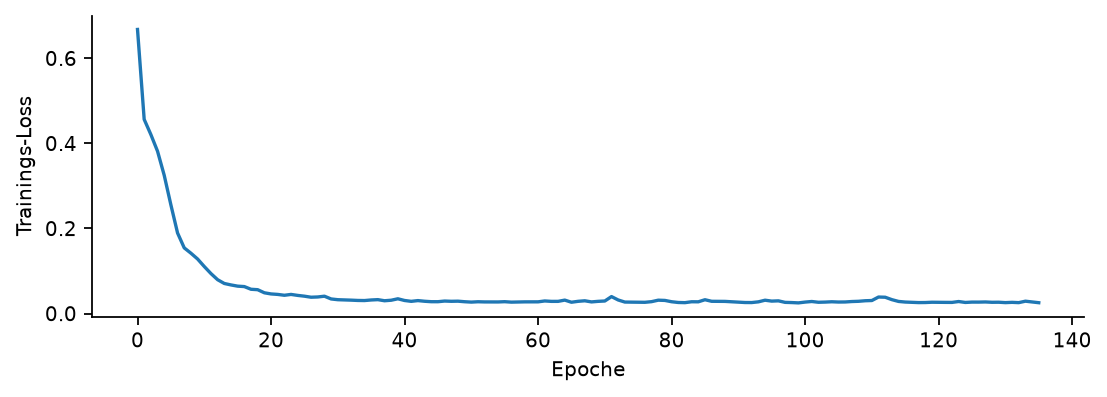

In [35]:

from sklearn.neural_network import MLPRegressor, MLPClassifier
rng = np.random.default_rng(42)
Xm = np.sort(rng.uniform(-3.5, 3.5, 500)).reshape(-1, 1)
ym = 1.3*np.sin(1.4*Xm[:,0]) + .25*Xm[:,0]
ym += rng.normal(0, .22, len(Xm))
a, b, c, d = train_test_split(Xm, ym, test_size=.25, random_state=42)
mlp = make_pipeline(StandardScaler(), MLPRegressor(
    hidden_layer_sizes=(32,16), learning_rate_init=.01,
    alpha=.001, batch_size=32, max_iter=1200,
    early_stopping=True, validation_fraction=.15,
    n_iter_no_change=40, random_state=42))
mlp.fit(a, c)
p = mlp.predict(b)
print("MAE:", round(mean_absolute_error(d, p), 3),
      "R2:", round(r2_score(d, p), 3))
print("Epochen:", mlp[-1].n_iter_)
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.plot(mlp[-1].loss_curve_)
ax.set(xlabel="Epoche", ylabel="Trainings-Loss")
fig.tight_layout()
plt.show()

**Klassifikation**

MLPClassifier(hidden_layer_sizes=(32,16), early_stopping=True, random_state=42) in derselben Skalierungs-Pipeline verwenden. Bei Multiclass predict_proba mit einer Wahrscheinlichkeit je Klasse; Bewertung wie auf Seite 20.

**Parameter**

hidden_layer_sizes legt Breite und Anzahl der Hidden Layer fest; learning_rate_init die Schrittweite von Adam, alpha die L2-Strafe, batch_size die Beispiele pro Update. Training und Validierung gemeinsam ansehen; allein eine fallende Trainings-Loss-Kurve reicht nicht.

**Gruppen und Zeit**

Das interne early_stopping=True verwendet einen eigenen Zufallssplit. Bei Zeitreihen oder Gruppen ist das nicht automatisch passend. Dann eine explizite Validierung mit passender Struktur und kontrollierter Trainingsschleife verwenden.

## 36 CNN mit PyTorch

Convolutional Neural Networks nutzen die räumliche Struktur von Bildern. Faltungen lernen lokale Filter, ReLU erzeugt Nichtlinearität und Pooling reduziert die räumliche Auflösung.

**Merksatz:** CrossEntropyLoss erwartet rohe Logits und Klassenindizes als long. Vor der Loss kein Softmax anwenden; für Wahrscheinlichkeiten erst nach dem Training.

Kursbezug: Set 14: 02_cnn_filter_pooling_und_feature_maps.ipynb; cv_tools.py

Test: {'loss': 0.116, 'accuracy': 0.964}
Eingabe: (2, 1, 8, 8)


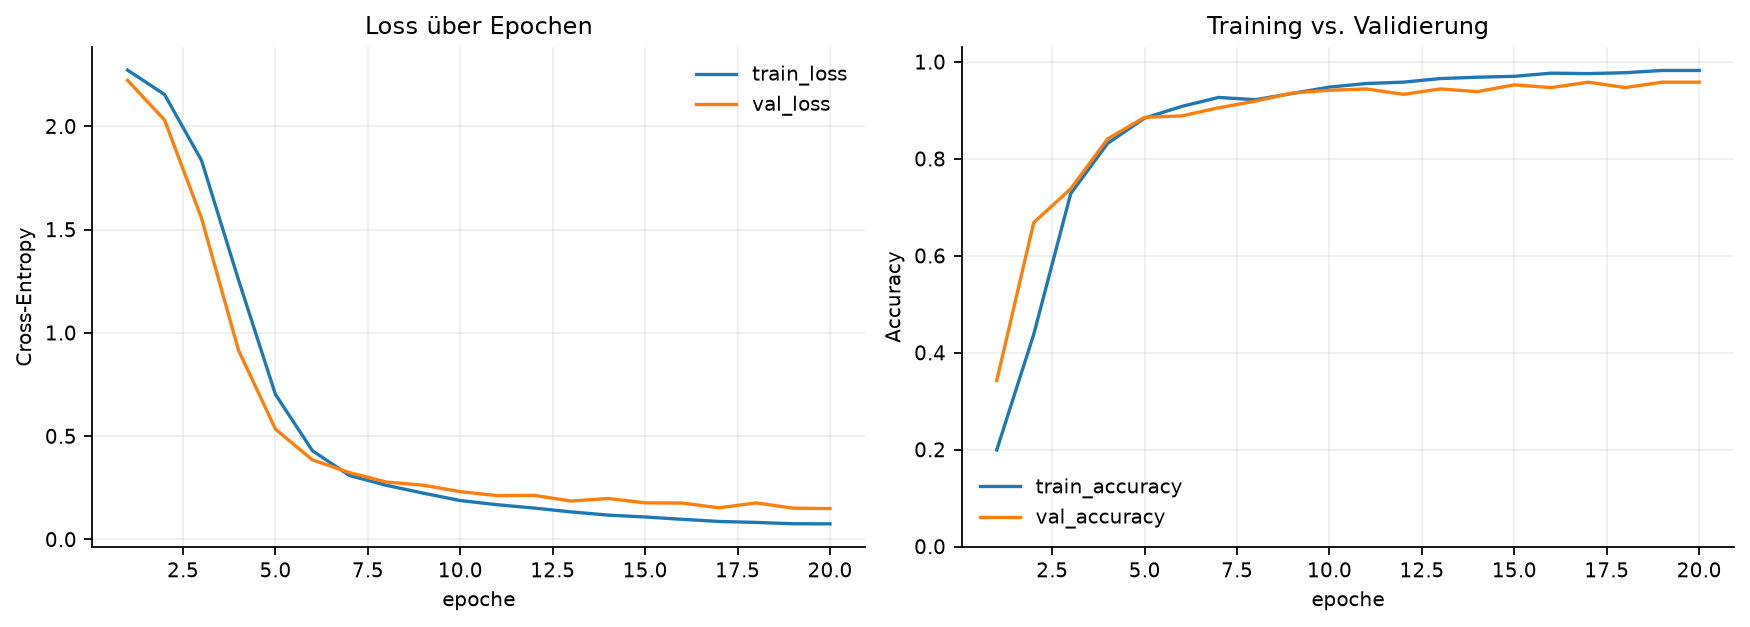

In [36]:

import torch
sys.path.insert(0, str(ROOT / "set14-neuronale-netze-nn2"))
from cv_tools import (cpu_setup, ziffern_split, loader,
    KleinesCNN, trainiere, auswerten, lernkurven)
cpu_setup()
bilder, labels_nn, split = ziffern_split()  # 60/20/20
tr_loader = loader(bilder[split["train"]],
    labels_nn[split["train"]], shuffle=True)
va_loader = loader(bilder[split["val"]], labels_nn[split["val"]])
te_loader = loader(bilder[split["test"]], labels_nn[split["test"]])
cnn = KleinesCNN()
hist = trainiere(cnn, tr_loader, va_loader, epochen=20, lr=.003)
metriken, probs_nn, echte_nn = auswerten(cnn, te_loader)
print("Test:", {k: round(v, 3) for k,v in metriken.items()})
print("Eingabe:", tuple(bilder[:2].shape))
lernkurven(hist)
plt.show()

**Training in sechs Schritten**

modell.train(); optimizer.zero_grad(); logits = modell(x); loss = loss_fn(logits,y); loss.backward(); optimizer.step(). cv_tools.trainiere führt diese Schritte für alle Batches aus und lädt anschließend die Gewichte mit dem niedrigsten Validierungs-Loss.

**Formen im Kurs**

Digits enthält 8×8-Graubilder: Batchform (N,1,8,8), Pixel geteilt durch 16. Zwei Conv-ReLU-Pooling-Blöcke erzeugen (N,16,2,2), danach Flatten und Linear(64,10). Das kleine CNN hat 1898 trainierbare Parameter.

**Auswerten**

modell.eval() schaltet Trainingsverhalten um; torch.inference_mode() verhindert Gradientenaufbau. Gewichte nicht anhand des Tests auswählen. Lernkurven, Konfusionsmatrix und falsch erkannte Bilder ergänzen; bei realen Bildern nach Aufnahmequelle splitten.

## 37 CNN Fehler und Filter ansehen

Konfusionsmatrix, falsch klassifizierte Bilder und gelernte Filter ergänzen Lernkurven. Sie zeigen, welche Ziffern verwechselt werden und welche lokalen Muster die erste Faltung gelernt hat.

**Merksatz:** Filterbilder helfen beim Verstehen der Architektur. Einzelne Filter sind keine vollständige Erklärung einer konkreten Vorhersage.

Kursbezug: Set 14: 02_cnn_filter_pooling_und_feature_maps.ipynb; cv_tools.py

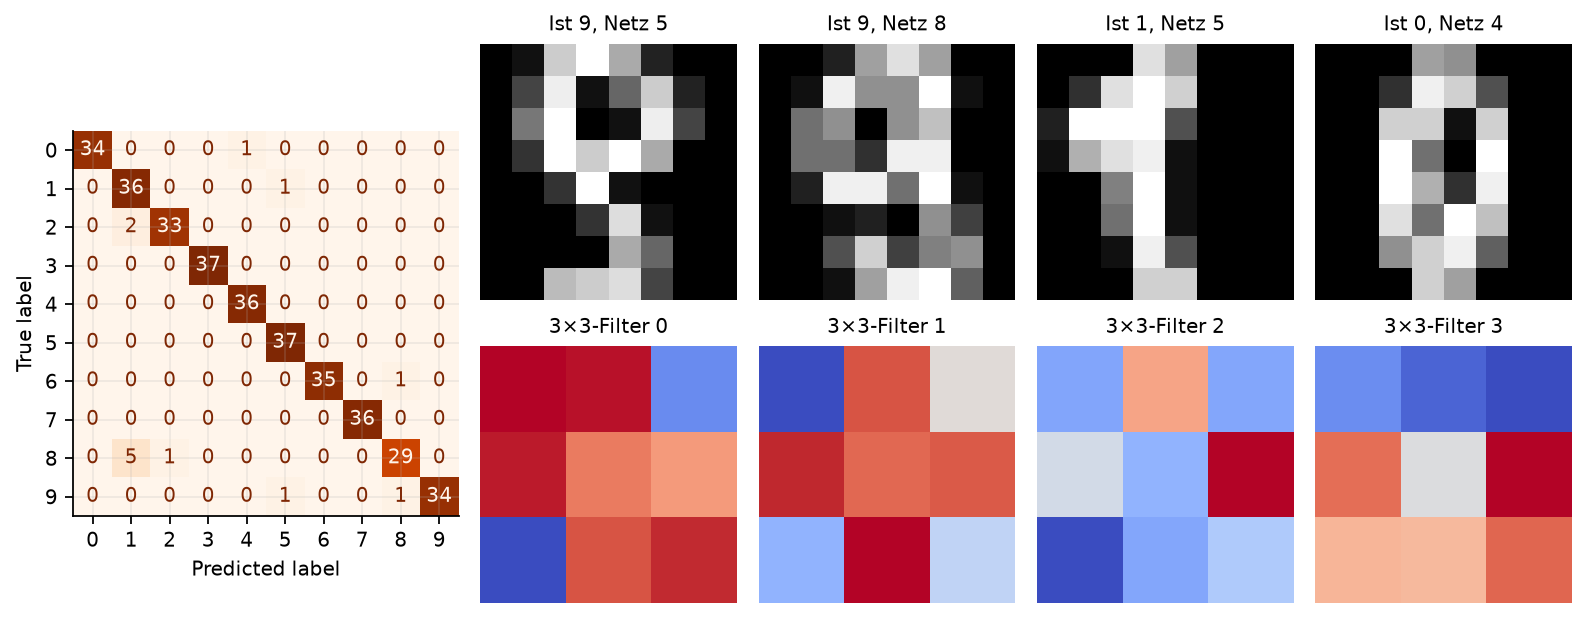

In [37]:

from sklearn.metrics import ConfusionMatrixDisplay
predicted_nn = probs_nn.argmax(1)
wrong_nn = (predicted_nn != echte_nn).nonzero().flatten()[:4]
fig = plt.figure(figsize=(10, 4))
gs = fig.add_gridspec(2, 5, width_ratios=[1.5,1,1,1,1])
ConfusionMatrixDisplay.from_predictions(echte_nn.numpy(),
    predicted_nn.numpy(), ax=fig.add_subplot(gs[:,0]),
    colorbar=False, cmap="Oranges")
for j in range(4):
    a = fig.add_subplot(gs[0,j+1]); a.axis("off")
    if j < len(wrong_nn):
        idx = int(wrong_nn[j])
        a.imshow(bilder[split["test"]][idx,0], cmap="gray")
        a.set_title(f"Ist {int(echte_nn[idx])}, Netz {int(predicted_nn[idx])}", fontsize=9)
    b = fig.add_subplot(gs[1,j+1]); b.axis("off")
    b.imshow(cnn.features[0].weight[j,0].detach().numpy(), cmap="coolwarm")
    b.set_title(f"3×3-Filter {j}", fontsize=9)
fig.tight_layout()
plt.show()

**Konfusionsmatrix**

Diagonale Zellen sind korrekte Vorhersagen, andere Zellen Verwechslungen. Zeilen sind echte Klassen, Spalten Vorhersagen. Die ausgewählten Fehlerbilder stammen aus genau diesem Testlauf.

**Filter und Feature Maps**

Die untere Reihe zeigt vier gelernte 3×3-Kernel. Feature Maps erhält man mit cnn.features[:2](probe) nach Faltung und ReLU. Testfehler dienen hier der abschließenden Diagnose, nicht einer anschließenden Optimierung anhand derselben Testdaten.

## 38 Transfer Learning und Modellkopf

Transfer Learning verwendet einen bereits gelernten Merkmalsextraktor und trainiert nur einen kleinen neuen Kopf. Im Kurs liefert ein eingefrorenes MobileNet Bildmerkmale für die Ziffernklassifikation.

**Merksatz:** Einfrieren betrifft Gewichte und zustandsbehaftete Schichten wie BatchNorm. Eingabeaufbereitung und Feature-Skalierung sind Teil des Modells.

Kursbezug: Set 14: 03_transfer_learning_nur_der_kopf.ipynb

Im Original-Transfer-Notebook ausführen:

```python
# Im Transfer-Notebook nach features=extrahiere_features(...):
train_features = features[split["train"]]
with torch.no_grad():
    modell.feature_mean.copy_(train_features.mean(0))
    modell.feature_std.copy_(train_features.std(0).clamp_min(1e-4))
z = (features-modell.feature_mean) / modell.feature_std
tl = loader(z[split["train"]], labels[split["train"]], shuffle=True)
vl = loader(z[split["val"]], labels[split["val"]])
test_loader = loader(z[split["test"]], labels[split["test"]])
historie = trainiere(modell.head, tl, vl, epochen=24, lr=.003)
metriken, probs, echte = auswerten(modell.head, test_loader)
print(metriken)
```

**Voraussetzung des Ausschnitts**

Dieses Rezept ist ein gezielter Ausschnitt aus dem Transfer-Notebook und wird dort nach der Feature-Extraktion ausgeführt. modell ist FrozenMobileNet, features sind dessen unveränderte Backbone-Ausgaben; bilder, labels, split und Hilfsfunktionen sind dort definiert. Der begleitende Cheat-Sheet-Lauf führt diesen Ausschnitt nicht automatisch aus.

**Aufbereitung**

Die Hilfsfunktion mobilenet_bilder macht aus 8×8-Graubildern RGB-Eingaben im erwarteten 224×224-Format und verwendet die zum Gewichtesatz passenden Normalisierungen. Das Hochskalieren erzeugt keine zusätzlichen Bilddetails.

**Ergebnis prüfen**

Das Kursnotebook verifiziert, dass Backbone-Gewichte und BatchNorm-Puffer unverändert bleiben und vollständiges Bildmodell und gecachte Features dieselben Vorhersagen liefern. Bei geändertem Backbone oder Preprocessing muss der Feature-Cache erneuert werden.

**Einmaliger Download**

Die ImageNet-Gewichte werden beim ersten Lauf geladen; danach ist der lokale Cache nutzbar. Ob Transfer auf die kleinen Ziffernbilder hilft, wird am gleichen Train/Val/Test-Split mit MLP und CNN geprüft.

## 39 PCA für Merkmalsreduktion

PCA erzeugt orthogonale lineare Richtungen maximaler Varianz. Sie kann korrelierte Merkmale verdichten, Rauschen reduzieren und eine zweidimensionale Ansicht ermöglichen.

**Merksatz:** Große Varianz ist nicht automatisch wichtig für das Ziel. PCA bei überwachter Bewertung innerhalb der Pipeline ausschließlich am Training lernen.

Kursbezug: Set 11: 01_pca_und_merkmalsreduktion.ipynb; Set 3: 06_pca_sensor_features.ipynb

Varianzanteile: [0.73  0.229]
Summe: 0.958


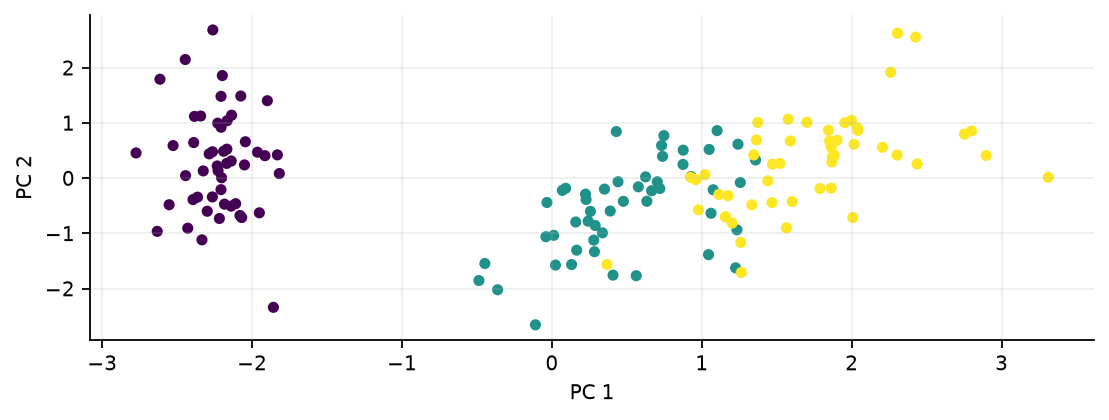

In [38]:

from sklearn.decomposition import PCA
# Iris nur zur explorativen 2D-Darstellung; keine Testgüte.
scaled = StandardScaler().fit_transform(iris.data)
pca = PCA(n_components=2, random_state=42)
z = pca.fit_transform(scaled)
print("Varianzanteile:", np.round(pca.explained_variance_ratio_, 3))
print("Summe:", round(pca.explained_variance_ratio_.sum(), 3))
fig, ax = plt.subplots(figsize=(7, 2.7))
ax.scatter(z[:,0], z[:,1], c=iris.target, cmap="viridis", s=16)
ax.set(xlabel="PC 1", ylabel="PC 2"); fig.tight_layout()
# Für Vorhersagen: make_pipeline(StandardScaler(),
#     PCA(n_components=.95), LogisticRegression(...))
# anschließend per CV innerhalb der Entwicklungsdaten bewerten.
plt.show()

**Ergebnis lesen**

explained_variance_ratio_ enthält den Anteil pro Komponente. np.cumsum(...) ergibt die kumulierte erklärte Varianz. n_components=.95 wählt bei geeigneter Solverwahl genügend Komponenten für mindestens 95 % Trainingsvarianz.

**Loadings und Rückprojektion**

components_ enthält die Richtungen im Merkmalsraum. pca.inverse_transform(z) rekonstruiert die skalierten Eingaben näherungsweise. Vorzeichen von Komponenten können wechseln, ohne dass sich ihre Bedeutung ändert.

**Skalierung bewusst entscheiden**

Standardisierung gewichtet jede Ausgangsvariable nach ihrer Streuung; unskalierte PCA bevorzugt große Skalen. Welche Variante fachlich sinnvoll ist, hängt von Einheiten und Messrauschen ab. Farbig getrennte Klassen im PCA-Plot sind keine validierte Klassifikation.

## 40 NMF und t-SNE

NMF zerlegt nichtnegative Daten in additive Bausteine und deren Gewichte. t-SNE erstellt eine nichtlineare 2D-Ansicht, die vor allem lokale Nachbarschaften sichtbar machen soll.

**Merksatz:** NMF ist eine Rekonstruktionsmethode; t-SNE eine explorative Darstellung. Abstände zwischen t-SNE-Inseln und Inselgrößen nicht als globale Geometrie interpretieren.

Kursbezug: Set 11: 02_nmf_und_tsne.ipynb

W / H: (240, 3) (3, 80)
Rekonstruktionsfehler: 0.719
Trustworthiness: 0.99


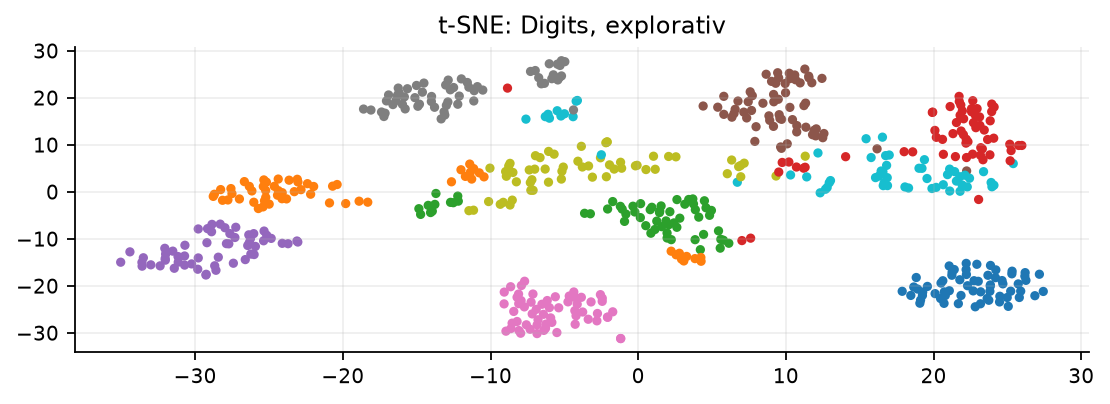

In [39]:

from sklearn.decomposition import NMF, PCA
from sklearn.manifold import TSNE, trustworthiness
# Additive nichtnegative Spektren wie im Kurs, kompakt simuliert.
wl = np.linspace(400, 800, 80)
H = np.array([np.exp(-.5*((wl-c)/25)**2) for c in [470,590,710]])
rng = np.random.default_rng(42)
spectra = rng.gamma(1.8, 1, (240,3)) @ H
nmf = NMF(n_components=3, init="nndsvda", max_iter=2000,
          tol=.001, random_state=42)
Wn = nmf.fit_transform(spectra)
print("W / H:", Wn.shape, nmf.components_.shape)
print("Rekonstruktionsfehler:", round(nmf.reconstruction_err_, 3))
digits = load_digits()
dx = StandardScaler().fit_transform(digits.data[:600])
reduced = PCA(n_components=30, random_state=42).fit_transform(dx)
embedded = TSNE(n_components=2, perplexity=30, init="pca",
    learning_rate="auto", random_state=42).fit_transform(reduced)
print("Trustworthiness:", round(trustworthiness(reduced, embedded), 3))
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.scatter(embedded[:,0], embedded[:,1], c=digits.target[:600],
           cmap="tab10", s=10)
ax.set(title="t-SNE: Digits, explorativ"); fig.tight_layout()
plt.show()

**NMF-Voraussetzungen**

Alle Eingaben müssen >= 0 sein. Zentrierte Standardisierung passt daher nicht davor. X ≈ W @ H; Komponentenanzahl und Rekonstruktionsfehler gemeinsam mit fachlicher Interpretierbarkeit prüfen. Nichtnegativität durch Abschneiden ist nur dann sinnvoll, wenn fachlich begründet.

**t-SNE-Voraussetzungen**

perplexity muss kleiner als die Zahl der Datenpunkte sein. Mehrere Seeds und Perplexities prüfen; sklearn-t-SNE besitzt keine normale transform-Methode für neue Daten. Trustworthiness bewertet lokale Nachbarschaftserhaltung, keine Klassen- oder Clusterwahrheit.

## 41 NMF Bausteine und Rekonstruktion

NMF lässt sich direkt an den gelernten Komponenten prüfen. Eine rekonstruierte Messung zeigt, ob die additive Zerlegung die Eingabestruktur erfasst.

**Merksatz:** Ein kleiner Rekonstruktionsfehler beweist nicht, dass jeder gefundene Baustein einer eindeutigen physikalischen Quelle entspricht.

Kursbezug: Set 11: 02_nmf_und_tsne.ipynb

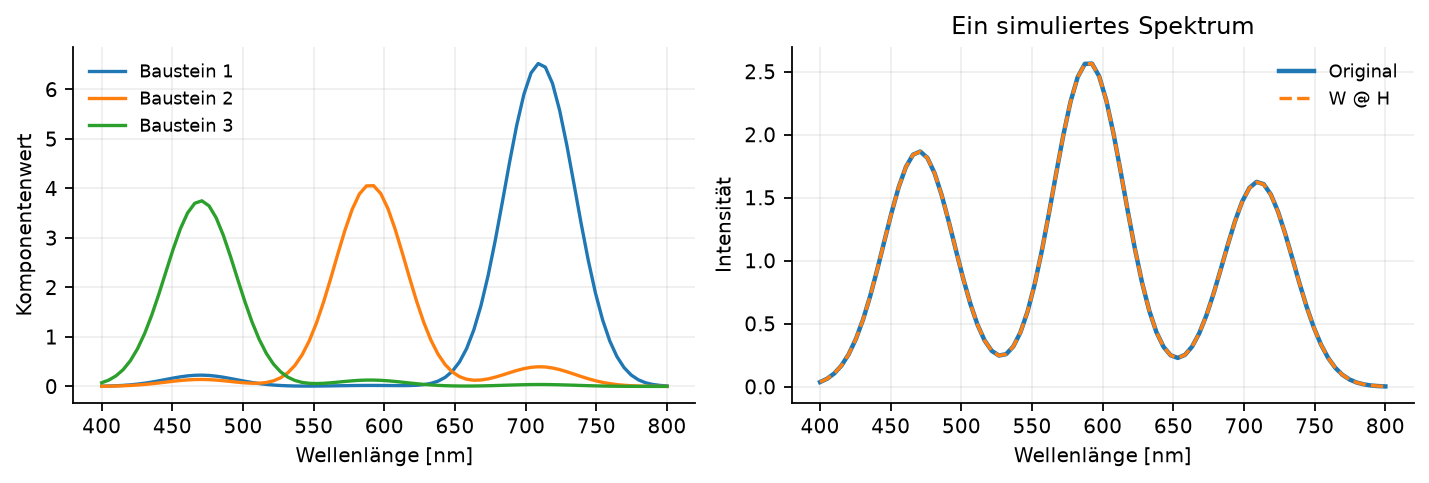

In [40]:

fig, ax = plt.subplots(1, 2, figsize=(9, 3.1))
for i, component in enumerate(nmf.components_, 1):
    ax[0].plot(wl, component, label=f"Baustein {i}")
ax[0].set(xlabel="Wellenlänge [nm]", ylabel="Komponentenwert")
ax[0].legend(fontsize=8)
reconstruction_vis = Wn @ nmf.components_
ax[1].plot(wl, spectra[0], label="Original", lw=2)
ax[1].plot(wl, reconstruction_vis[0], "--", label="W @ H")
ax[1].set(xlabel="Wellenlänge [nm]", ylabel="Intensität",
          title="Ein simuliertes Spektrum")
ax[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Bild lesen**

Die Komponenten lokalisieren die drei simulierten Spektralbereiche. Die Rekonstruktion liegt nahe an der Originalkurve. Komponentenreihenfolge und Skalierung können sich ändern, obwohl das Produkt W @ H fast gleich bleibt.

**Diagnose ausbauen**

Rekonstruktionsfehler für einzelne Messungen statt nur als Gesamtsumme ansehen. Falls neue Spektren beurteilt werden, NMF am Training fitten und neue Daten mit transform in die gelernten Komponenten zerlegen.

## 42 KMeans und hierarchische Cluster

KMeans sucht kompakte Gruppen um Zentren. Agglomeratives Clustering führt schrittweise nahe Gruppen zusammen und macht eine hierarchische Struktur zugänglich.

**Merksatz:** Cluster sind gefundene Strukturen, keine automatisch bekannten Klassen. Skalierung, Distanz und gewählte Clusterzahl verändern das Ergebnis.

Kursbezug: Set 11: 03_kmeans_und_clusterbewertung.ipynb; 04_hierarchisch_dbscan_und_gmm.ipynb

Silhouette KMeans: 0.84
Silhouette Hierarchie: 0.84
ARI zur simulierten Wahrheit: 1.0


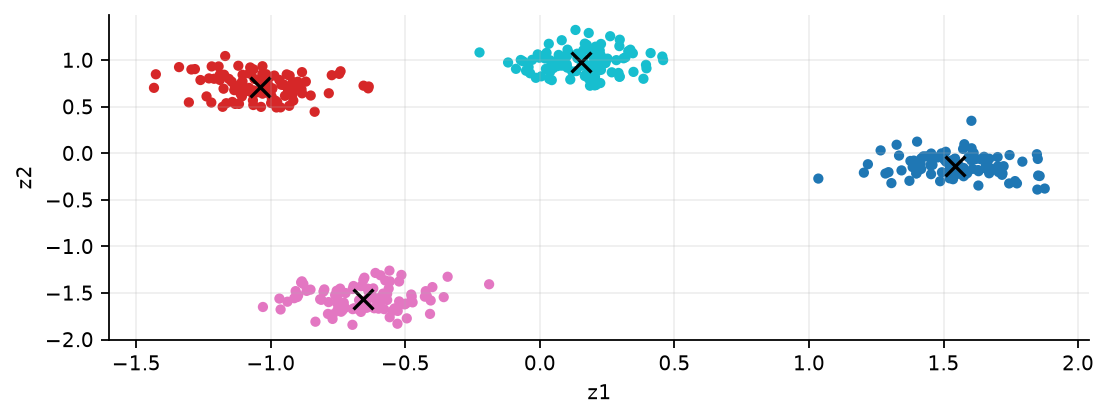

In [41]:

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
blobs, hidden = make_blobs(n_samples=400, centers=4,
    cluster_std=.8, random_state=42)
zb = StandardScaler().fit_transform(blobs)
km = KMeans(n_clusters=4, n_init=10, random_state=42)
lab = km.fit_predict(zb)
hierarchical = AgglomerativeClustering(n_clusters=4, linkage="ward")
lab_h = hierarchical.fit_predict(zb)
print("Silhouette KMeans:", round(silhouette_score(zb, lab), 3))
print("Silhouette Hierarchie:", round(silhouette_score(zb, lab_h), 3))
print("ARI zur simulierten Wahrheit:",
      round(adjusted_rand_score(hidden, lab), 3))
fig, ax = plt.subplots(figsize=(7, 2.7))
ax.scatter(zb[:,0], zb[:,1], c=lab, cmap="tab10", s=13)
ax.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1],
           marker="x", c="black", s=80)
ax.set(xlabel="z1", ylabel="z2"); fig.tight_layout()
plt.show()

**Clusterzahl wählen**

Elbow-Plot mit km.inertia_ für mehrere k und Silhouette-Plot ergänzen. Silhouette liegt zwischen -1 und 1, benötigt 2 bis n-1 Cluster und bevorzugt häufig kompakte, getrennte Gruppen. Die höchste Zahl ist nicht automatisch die fachlich beste Lösung.

**Hierarchie**

Ward minimiert den Zuwachs innerhalb der Cluster und verwendet euklidische Distanzen. Andere Linkages beantworten andere Distanzfragen. sklearn-AgglomerativeClustering besitzt keine gewöhnliche predict-Methode für neue Punkte.

**Labels nur nachträglich**

adjusted_rand_score ist invariant gegenüber umbenannten Cluster-IDs und braucht externe Referenzlabels. Hier sind hidden nur zur Illustration bekannt; sie gehen nicht in fit ein. Ein gutes Ergebnis auf make_blobs ist keine reale Anwendungsgarantie.

## 43 DBSCAN und Gaussian Mixtures

DBSCAN findet dichte Gebiete beliebiger Form und markiert isolierte Punkte als Noise. Gaussian Mixture Models beschreiben Daten als Mischung mehrerer Normalverteilungen und liefern weiche Zugehörigkeiten.

**Merksatz:** DBSCAN bestimmt Noise und Cluster aus eps und min_samples. GMM benötigt eine Komponentenanzahl und Annahmen über die Kovarianzstruktur.

Kursbezug: Set 11: 04_hierarchisch_dbscan_und_gmm.ipynb

In [42]:

from sklearn.cluster import DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
moon, _ = make_moons(n_samples=620, noise=.075, random_state=42)
zm = StandardScaler().fit_transform(moon)
db = DBSCAN(eps=.22, min_samples=8).fit(zm)
lab_db = db.labels_
mask = lab_db != -1
k = len(set(lab_db[mask]))
print("Cluster:", k, "Noise-Anteil:", round((~mask).mean(), 3))
if 1 < k < mask.sum():
    print("Silhouette ohne Noise:",
          round(silhouette_score(zm[mask], lab_db[mask]), 3))
gmm = GaussianMixture(n_components=4, covariance_type="full",
                      n_init=5, random_state=42).fit(zb)
print("GMM Zugehörigkeiten:\n", np.round(gmm.predict_proba(zb[:3]), 3))
print("BIC:", round(gmm.bic(zb), 1))
plt.show()

Cluster: 2 Noise-Anteil: 0.005
Silhouette ohne Noise: 0.39
GMM Zugehörigkeiten:
 [[0. 1. 0. 0.]
 [0. 0. 0. 1.]
 [0. 1. 0. 0.]]
BIC: 314.4


**DBSCAN einstellen**

eps ist ein Radius in der gewählten skalierten Distanz, min_samples die Mindestzahl einschließlich des Punkts selbst. k-Distanz-Plot und Stabilität über mehrere Parameter prüfen. Bei stark wechselnder Dichte kann ein einzelnes eps scheitern.

**Noise ist keine Klasse**

Label -1 bezeichnet Noise. Beim Silhouette-Score Noise ausschließen und gleichzeitig Noise-Anteil sowie Clusterzahl nennen; andernfalls kann eine Lösung durch das Aussortieren schwieriger Punkte besser aussehen.

**GMM bewerten**

Kleineres BIC/AIC bevorzugt bei gleichen Daten eine bessere Anpassung nach Komplexitätsstrafe. predict_proba sind modellinterne Zugehörigkeiten, keine extern validierten Klassenwahrscheinlichkeiten. Ein GMM-Cluster ist ellipsoid; mehrere Komponenten können zusammen eine fachliche Gruppe beschreiben.

## 44 Clusterformen und weiche Zuordnung

DBSCAN ist bei gebogenen dichten Gruppen hilfreich, GMM beschreibt ellipsoidartige Komponenten. Eine farbige Darstellung macht die unterschiedlichen Modellannahmen deutlicher als ein Score allein.

**Merksatz:** Eine niedrigere Silhouette kann bei gebogenen Gruppen trotzdem zu einer fachlich sinnvollen Lösung gehören. Score und Geometrie gemeinsam lesen.

Kursbezug: Set 11: 04_hierarchisch_dbscan_und_gmm.ipynb

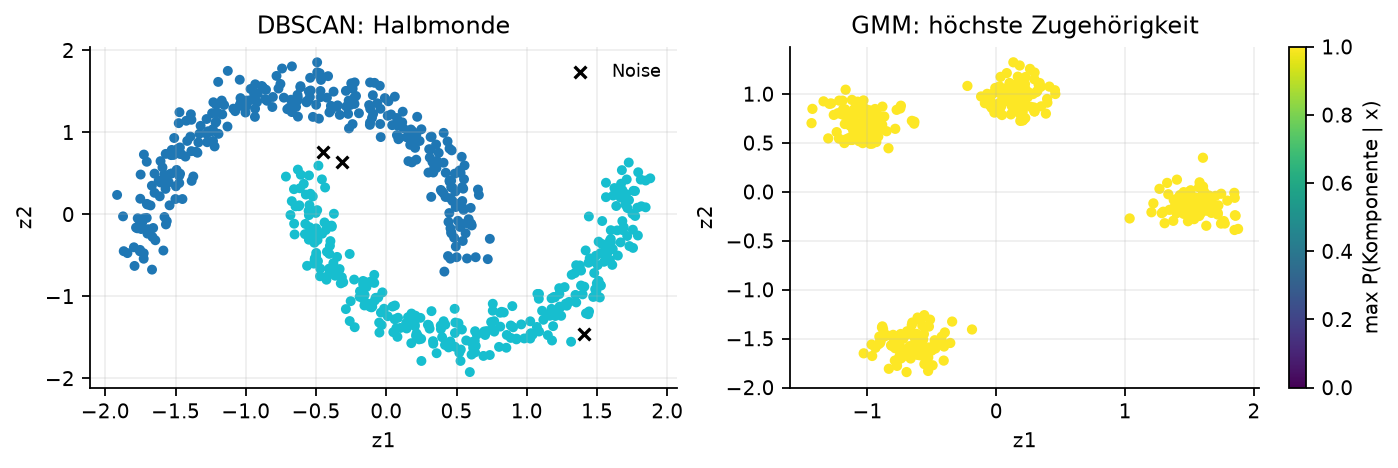

In [43]:

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].scatter(zm[mask,0], zm[mask,1], c=lab_db[mask], cmap="tab10", s=12)
ax[0].scatter(zm[~mask,0], zm[~mask,1], c="black", marker="x",
               label="Noise", s=28)
ax[0].set(title="DBSCAN: Halbmonde", xlabel="z1", ylabel="z2")
ax[0].legend(fontsize=8)
prob_vis = gmm.predict_proba(zb)
sc = ax[1].scatter(zb[:,0], zb[:,1], c=prob_vis.max(axis=1),
                    vmin=0, vmax=1, cmap="viridis", s=13)
ax[1].set(title="GMM: höchste Zugehörigkeit", xlabel="z1", ylabel="z2")
fig.colorbar(sc, ax=ax[1], label="max P(Komponente | x)")
fig.tight_layout()
plt.show()

**Bild lesen**

DBSCAN folgt den zwei Halbmondformen und markiert wenige Punkte als Noise. Die vier simulierten Blob-Gruppen rechts sind so deutlich getrennt, dass die höchste modellinterne GMM-Zugehörigkeit fast überall nahe 1 liegt.

**Vorsicht bei hoher Sicherheit**

Hohe Zugehörigkeit heißt nur, dass eine Komponente relativ zu den anderen dominiert. Ein weit entfernter neuer Punkt kann trotzdem eine hohe relative Zugehörigkeit haben; für Anomalien zusätzlich die absolute Dichte prüfen.

## 45 Anomalien und Schwellenwerte

Anomalieerkennung bewertet, wie ungewöhnlich ein Punkt gegenüber einer Referenz ist. Isolation Forest isoliert seltene Strukturen; OneClassSVM grenzt eine Normalregion ein.

**Merksatz:** Score-Richtung ausdrücklich prüfen. Einen Schwellenwert an unabhängigen Validierungsdaten festlegen und Fehlalarme sowie verpasste Anomalien getrennt berichten.

Kursbezug: Set 11: 05_anomalieerkennung_und_thresholds.ipynb

In [44]:

from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score
rng = np.random.default_rng(42)
normal_train = rng.normal(size=(500,2))
normal_val = rng.normal(size=(200,2))
test_normal = rng.normal(size=(200,2))
test_bad = rng.uniform(4, 7, size=(20,2))
detector = IsolationForest(n_estimators=200, random_state=42)
detector.fit(normal_train)
# Bei score_samples: kleiner = ungewöhnlicher; Vorzeichen drehen.
val_score = -detector.score_samples(normal_val)
threshold = np.quantile(val_score, .99)
test_x = np.vstack([test_normal, test_bad])
test_y = np.r_[np.zeros(200), np.ones(20)]
score = -detector.score_samples(test_x)
flag = score >= threshold
print("Precision:", round(precision_score(test_y, flag), 3),
      "Recall:", round(recall_score(test_y, flag), 3))
print("Fehlalarmrate normal:", round(flag[:200].mean(), 3))
plt.show()

Precision: 0.87 Recall: 1.0
Fehlalarmrate normal: 0.015


**Was der Quantilwert bedeutet**

Das 99%-Quantil der normalen Validierung setzt etwa 1 % dieser Referenz oberhalb der Schwelle. Das garantiert keine 1 % Fehlalarme auf zukünftigen Daten. Hier sind die Anomalien absichtlich stark getrennt und damit leicht erkennbar.

**Andere Verfahren**

OneClassSVM benötigt typischerweise Standardisierung; nu steuert die Lösung, ist aber keine garantierte zukünftige Fehlalarmrate. GMM-Dichte oder PCA-Rekonstruktionsfehler können ebenfalls Scores liefern, wenn ihre Modellannahmen passen.

**Betrieb**

Normale Änderungen von Last, Umgebung und Sensoralter können wie Fehler aussehen. Alarmrate pro Zeit, Verzögerung bis zur Erkennung und Fehlalarme pro Maschine sind oft relevanter als ein einzelner zeilenweiser F1.

## 46 Anomaliescores und Alarmgrenzen

Score-Verteilungen zeigen, wie stark Normalfälle und Anomalien überlappen. Ein räumlicher Plot ergänzt, an welchen Stellen das gewählte Verfahren tatsächlich Alarm auslöst.

**Merksatz:** Der Schwellenwert verschiebt den Kompromiss zwischen Fehlalarm und verpasstem Fehler. Für die reale Anwendung müssen Anomalien und Normalvarianten repräsentativ sein.

Kursbezug: Set 11: 05_anomalieerkennung_und_thresholds.ipynb

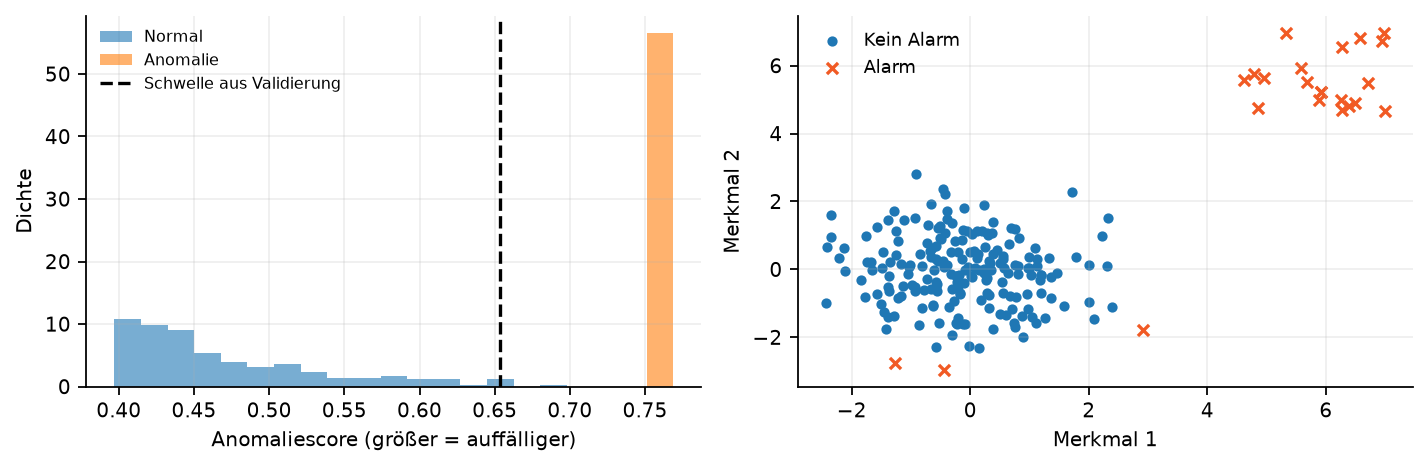

In [45]:

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
bins_vis = np.linspace(score.min(), score.max(), 22)
ax[0].hist(score[test_y==0], bins=bins_vis, alpha=.6,
            density=True, label="Normal")
ax[0].hist(score[test_y==1], bins=bins_vis, alpha=.6,
            density=True, label="Anomalie")
ax[0].axvline(threshold, color="black", ls="--", label="Schwelle aus Validierung")
ax[0].set(xlabel="Anomaliescore (größer = auffälliger)", ylabel="Dichte")
ax[0].legend(fontsize=7)
ax[1].scatter(test_x[~flag,0], test_x[~flag,1], s=13, label="Kein Alarm")
ax[1].scatter(test_x[flag,0], test_x[flag,1], s=25, marker="x",
              color="#f15a24", label="Alarm")
ax[1].set(xlabel="Merkmal 1", ylabel="Merkmal 2")
ax[1].legend(fontsize=8); fig.tight_layout()
plt.show()

**Bild lesen**

In diesem bewusst einfachen Beispiel liegen die simulierten Anomalien weit außerhalb der normalen Wolke. Einige normale Randpunkte überschreiten ebenfalls die festgelegte Schwelle; sie sind Fehlalarme.

**Nicht am Test nachjustieren**

Die vertikale Grenze wurde zuvor aus normalen Validierungsdaten bestimmt. Ihre Lage nach Betrachtung dieser Testhistogramme zu ändern würde einen neuen unabhängigen Test erfordern.

## 47 Erklären speichern und wiederverwenden

Eine Vorhersage ist erst reproduzierbar, wenn Vorverarbeitung, Modell, Spalten und Umgebung zusammenpassen. Erklärungen helfen beim Plausibilitätscheck, ersetzen aber keinen passenden Split.

**Merksatz:** Die vollständige Pipeline speichern. Einen eigenen Transformer über eine importierbare Python-Datei verfügbar halten und nach dem Laden die Vorhersagen vergleichen.

Kursbezug: Set 5: 05_xai_koeffizienten.ipynb; Set 15: 01/02/03; custom_transformer_einfach.py

In [46]:

from sklearn.inspection import permutation_importance
# Diagnose auf separaten Bewertungsdaten, keine kausale Aussage.
importance = permutation_importance(iris_model, ie, je,
    scoring="accuracy", n_repeats=10, random_state=42)
print(pd.Series(importance.importances_mean,
                index=iris.data.columns).round(3))

import joblib
artifact = ROOT / "tmp/ml-cheatsheet/iris_pipeline.joblib"
artifact.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(iris_model, artifact)
loaded = joblib.load(artifact)
print("Vorhersagen identisch:", np.array_equal(
    iris_model.predict(ie), loaded.predict(ie)))
plt.show()

sepal length (cm)    0.026
sepal width (cm)     0.076
petal length (cm)    0.187
petal width (cm)     0.197
dtype: float64
Vorhersagen identisch: True


**Interpretation**

Permutation Importance misst den Score-Verlust beim Mischen eines Eingabemerkmals. Bei korrelierten Merkmalen kann Wichtigkeit verteilt oder verdeckt sein. Bei einer kompletten Pipeline werden hier die ursprünglichen Iris-Eingaben permutiert, nicht die ergänzten Flächen einzeln.

**Modellpaket**

Zusätzlich Spaltennamen und Reihenfolge, Klassenbezeichnungen, Paketversionen, Trainingsdatenversion und Bewertungsprotokoll sichern. joblib/pickle nur aus vertrauenswürdigen Quellen laden. Eigene Klassen und kompatible Bibliotheken müssen beim Laden verfügbar sein.

**PyTorch**

torch.save(modell.state_dict(), pfad) speichert Gewichte; die Architektur muss separat rekonstruiert werden. Danach load_state_dict(torch.load(pfad, map_location="cpu", weights_only=True), strict=True) und modell.eval(). Preprocessing, Klassen und Modellkonfiguration ebenfalls mitführen.

**Offizielle API-Referenzen**

scikit-learn.org/stable/common_pitfalls.html; scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html; statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html. Kursdateien sind die primäre Zuordnung der Beispiele; Stand des Hefts: 20.11.2026.

## 48 Ein eigener Transformer im Detail

TransformerMixin ergänzt fit_transform, BaseEstimator die Parameter-Schnittstelle für Pipelines und Parametersuchen. Das folgende Minimalbeispiel zeigt die Rechenregel aus Set 15 vollständig.

**Merksatz:** transform verändert die übergebene Tabelle nicht. Eingaben müssen dieselben erwarteten Spalten enthalten; die ergänzten Merkmale bleiben für neue Daten identisch definiert.

Kursbezug: Set 15: custom_transformer_einfach.py; 02b_sklearn_eigener_transformer_schritt_fuer_schritt.ipynb

In [47]:

from sklearn.base import BaseEstimator, TransformerMixin

class FlaechenDemo(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        return self  # feste Regel, keine Statistik zu lernen

    def transform(self, X):
        out = X.copy()
        out["kelch_flaeche"] = (X["sepal length (cm)"]
                                 * X["sepal width (cm)"])
        out["blueten_flaeche"] = (X["petal length (cm)"]
                                   * X["petal width (cm)"])
        return out

demo = FlaechenDemo()
erweitert = demo.fit_transform(iris.data.iloc[:2])
print("Vorher:", iris.data.iloc[:2].shape,
      "Nachher:", erweitert.shape)
print(erweitert[["kelch_flaeche", "blueten_flaeche"]].round(2))
plt.show()

Vorher: (2, 4) Nachher: (2, 6)
   kelch_flaeche  blueten_flaeche
0          17.85             0.28
1          14.70             0.28


**Warum in einer .py-Datei?**

Eine in einer Notebookzelle definierte Klasse ist beim Laden in einem frischen Prozess nicht automatisch verfügbar. Für das gespeicherte Modell wird auf Seite 13 daher die importierbare Kursklasse FlaechenMerkmale aus custom_transformer_einfach.py verwendet.

**Wenn die Regel Parameter hat**

Optionen als gleichnamige Attribute in __init__ speichern, ohne dort Daten zu verarbeiten. Aus Training gelernte Attribute in fit üblicherweise mit einem Unterstrich am Ende benennen und in transform wiederverwenden.

**Fehlende Werte und Reihenfolge**

Fehlt eine Länge oder Breite, wird auch das Produkt NaN. Im Rezept folgt deshalb die Imputation auf die feste Feature-Bildung. Ob zuerst Rohgrößen imputiert oder Produkte imputiert werden sollen, ist eine bewusste fachliche Entscheidung.